<a href="https://colab.research.google.com/github/kahor09tkt-code/EDA-PRF-2025/blob/main/PRF_2025_Kahor_Takata.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entrega 1 | Análise Exploratória de Dados (EDA) dos Acidentes da PRF em 2025

**Base:** Acidentes 2025 agrupados por ocorrência, Polícia Rodoviária Federal.  
**Objetivo:** analisar qualidade dos dados, valores extremos, distribuições, associações e perspectivas para modelagem.
**Fonte oficial:** https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf



In [1]:
# Entrega 1: carregamento reprodutível da base da PRF 2025.
# Compatível com nomes acrescidos de números pelo Colab.
import pandas as pd
from pathlib import Path
from zipfile import ZipFile, is_zipfile

# Usa o ZIP já presente na sessão, evitando solicitar novo envio.
candidatos = [Path("datatran2025.zip"), Path("/content/datatran2025.zip"),
              Path("/mnt/data/datatran2025.zip")]
candidatos += sorted(Path(".").glob("datatran2025*.zip"),
                     key=lambda p: p.stat().st_mtime, reverse=True)
caminho_zip = next((p for p in candidatos if p.is_file() and is_zipfile(p)), None)

if caminho_zip is None:
    try:
        from google.colab import files
    except ImportError as erro:
        raise FileNotFoundError(
            "Baixe datatran2025.zip no portal de dados da PRF e coloque o ZIP na pasta atual."
        ) from erro
    print("Envie o arquivo ZIP dos acidentes de 2025, agrupados por ocorrência.")
    enviados = files.upload()
    caminho_zip = next((Path(nome) for nome in enviados
                        if nome.lower().endswith(".zip") and is_zipfile(nome)), None)
    if caminho_zip is None:
        raise FileNotFoundError("Nenhum arquivo ZIP válido foi enviado.")

with ZipFile(caminho_zip) as zip_file:
    arquivos = [nome for nome in zip_file.namelist()
                if nome.lower().endswith(".csv")]
    nome_csv = next((nome for nome in arquivos
                     if "datatran2025" in nome.lower()), None)
    if nome_csv is None:
        raise ValueError("ZIP sem o CSV esperado: datatran2025.csv")
    with zip_file.open(nome_csv) as arquivo:
        df = pd.read_csv(arquivo, sep=";", encoding="latin1",
                         decimal=",", low_memory=False)

colunas_obrigatorias = {"id", "mortos", "pessoas", "data_inversa", "horario",
                        "uf", "tipo_pista", "condicao_metereologica"}
if not colunas_obrigatorias.issubset(df.columns):
    raise ValueError("O arquivo carregado não corresponde à base PRF 2025 esperada.")
print("Base carregada:", caminho_zip.name)
print("Dimensões:", df.shape)
display(df.head())

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
sns.set_theme(style="whitegrid")


Envie o arquivo ZIP dos acidentes de 2025, agrupados por ocorrência.


Saving datatran2025 (1) (1).zip to datatran2025 (1) (1).zip
Base carregada: datatran2025 (1) (1).zip
Dimensões: (72529, 30)


,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
0,652493,2025-01-01,quarta-feira,06:20:00,SP,116,225.0,GUARULHOS,Reação tardia ou ineficiente do condutor,Tombamento,...,0,0,1,1,2,-23.485868,-46.540753,SPRF-SP,DEL01-SP,UOP01-DEL01-SP
1,652519,2025-01-01,quarta-feira,07:50:00,CE,116,546.2,PENAFORTE,Pista esburacada,Colisão frontal,...,0,1,4,1,6,-7.812288,-39.083333,SPRF-CE,DEL05-CE,UOP03-DEL05-CE
2,652522,2025-01-01,quarta-feira,08:45:00,PR,369,88.2,CORNELIO PROCOPIO,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,2,0,3,2,-23.182565,-50.637228,SPRF-PR,DEL07-PR,UOP05-DEL07-PR
3,652544,2025-01-01,quarta-feira,11:00:00,PR,116,74.0,CAMPINA GRANDE DO SUL,Reação tardia ou ineficiente do condutor,Saída de leito carroçável,...,0,4,0,1,2,-25.365177,-49.042230,SPRF-PR,DEL01-PR,UOP02-DEL01-PR
4,652549,2025-01-01,quarta-feira,09:30:00,MG,251,471.0,FRANCISCO SA,Velocidade Incompatível,Colisão frontal,...,1,1,2,2,4,-16.468013,-43.431213,SPRF-MG,DEL12-MG,UOP01-DEL12-MG


In [2]:
#linhas e colunas

print("Dimensões:", df.shape)

print("\nTipos das variáveis:")
df.info()

print("\nResumo estatístico:")
display(df.describe(include="all").T)

Dimensões: (72529, 30)

Tipos das variáveis:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72529 entries, 0 to 72528
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      72529 non-null  int64  
 1   data_inversa            72529 non-null  object 
 2   dia_semana              72529 non-null  object 
 3   horario                 72529 non-null  object 
 4   uf                      72529 non-null  object 
 5   br                      72529 non-null  int64  
 6   km                      72529 non-null  float64
 7   municipio               72529 non-null  object 
 8   causa_acidente          72529 non-null  object 
 9   tipo_acidente           72529 non-null  object 
 10  classificacao_acidente  72528 non-null  object 
 11  fase_dia                72529 non-null  object 
 12  sentido_via             72529 non-null  object 
 13  condicao_metereologica  72529 non-null  object

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,72529.0,NaN,NaN,NaN,700880.500862,26988.975438,652468.0,672804.0,703877.0,723739.0,758186.0
data_inversa,72529,365,2025-12-20,285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dia_semana,72529,7,sábado,11554,NaN,NaN,NaN,NaN,NaN,NaN,NaN
horario,72529,1412,19:00:00,1060,NaN,NaN,NaN,NaN,NaN,NaN,NaN
uf,72529,27,MG,9570,NaN,NaN,NaN,NaN,NaN,NaN,NaN
br,72529.0,NaN,NaN,NaN,208.502392,128.572019,0.0,101.0,155.0,319.0,495.0
km,72529.0,NaN,NaN,NaN,260.042406,227.921035,0.0,76.0,192.5,411.0,1257.0
municipio,72529,1844,BRASILIA,1011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
causa_acidente,72529,69,Ausência de reação do condutor,11469,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_acidente,72529,17,Colisão traseira,14360,NaN,NaN,NaN,NaN,NaN,NaN,NaN


A base de dados contém 72.529 ocorrências registradas em 2025, distribuídas em 30 variáveis. Cada linha representa um acidente, enquanto as colunas descrevem suas características, incluindo localização, condições meteorológicas, classificação do acidente e quantidade de envolvidos. Essa estrutura permite investigar tanto a distribuição dos acidentes quanto suas associações com fatores temporais e viários.

In [3]:
#Itens ausentes e duplicados

df["data"] = pd.to_datetime(
    df["data_inversa"],
    errors="coerce"
)

df["hora"] = pd.to_datetime(
    df["horario"],
    format="%H:%M:%S",
    errors="coerce"
).dt.hour

df["mes"] = df["data"].dt.month

df["ocorrencia_fatal"] = df["mortos"] > 0

print(df[["data", "hora", "mes", "ocorrencia_fatal"]].head())

nulos = pd.DataFrame({
    "Quantidade": df.isnull().sum(),
    "Percentual": df.isnull().mean() * 100
})

display(nulos.sort_values(
    "Quantidade", ascending=False
))

print("Linhas duplicadas:", df.duplicated().sum())
print("IDs repetidos:", df["id"].duplicated().sum())

print(df["condicao_metereologica"].value_counts())

        data  hora  mes  ocorrencia_fatal
0 2025-01-01     6    1             False
1 2025-01-01     7    1              True
2 2025-01-01     8    1             False
3 2025-01-01    11    1             False
4 2025-01-01     9    1             False


,Quantidade,Percentual
uop,38,0.052393
delegacia,22,0.030333
regional,2,0.002758
classificacao_acidente,1,0.001379
data_inversa,0,0.000000
id,0,0.000000
km,0,0.000000
dia_semana,0,0.000000
uf,0,0.000000
horario,0,0.000000


Linhas duplicadas: 0
IDs repetidos: 0
condicao_metereologica
Céu Claro           46375
Nublado             11435
Chuva                6438
Sol                  4201
Garoa/Chuvisco       2422
Ignorado             1000
Nevoeiro/Neblina      553
Vento                 104
Neve                    1
Name: count, dtype: int64


A inspeção identificou uma quantidade relativamente pequena de valores nulos literais, concentrados em variáveis administrativas. Não foram encontradas linhas integralmente duplicadas ou identificadores repetidos. Entretanto, categorias como "Ignorado" representam informação desconhecida e precisam ser consideradas no tratamento dos dados.


In [4]:
#Identificar inconsistências

df["soma_pessoas"] = (
    df["mortos"]
    + df["feridos_leves"]
    + df["feridos_graves"]
    + df["ilesos"]
    + df["ignorados"]
)

inconsistentes = df[
    df["pessoas"] != df["soma_pessoas"]
]

print("Registros inconsistentes:", len(inconsistentes))

display(inconsistentes[
    ["id", "pessoas", "soma_pessoas"]
].head())



Registros inconsistentes: 3823


,id,pessoas,soma_pessoas
1,652519,6,7
5,652569,4,5
22,652760,5,6
30,652812,4,5
33,652829,2,3


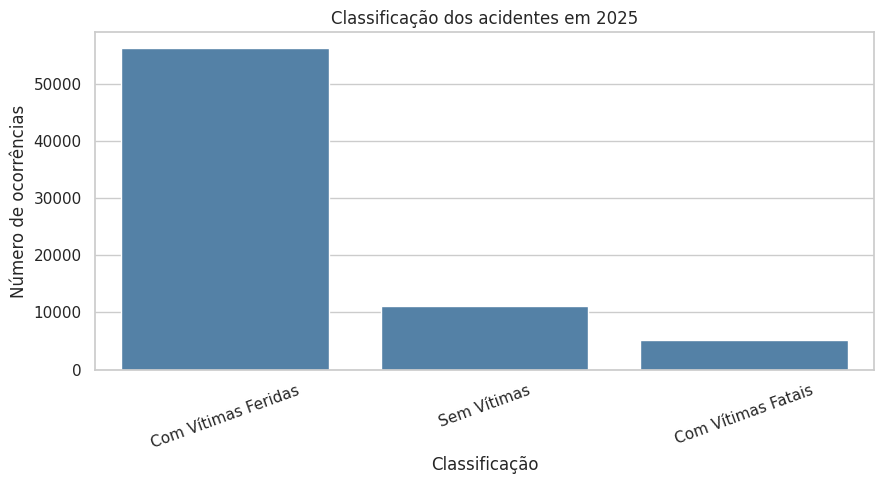

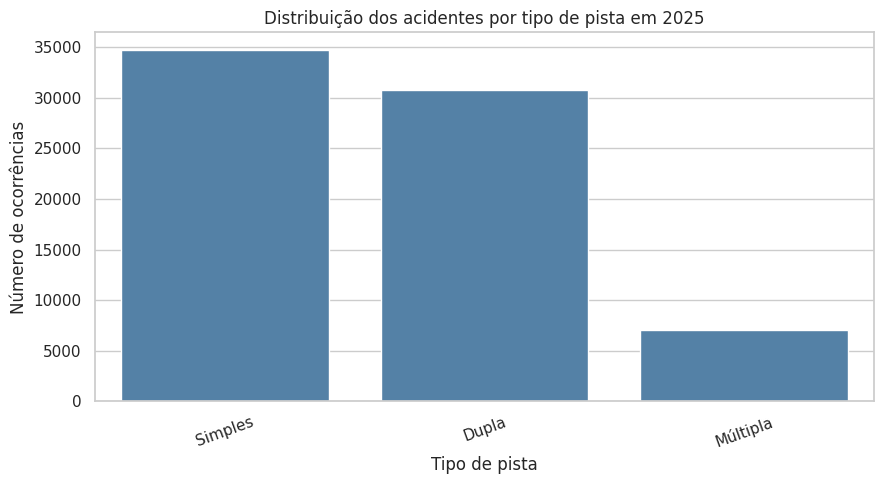

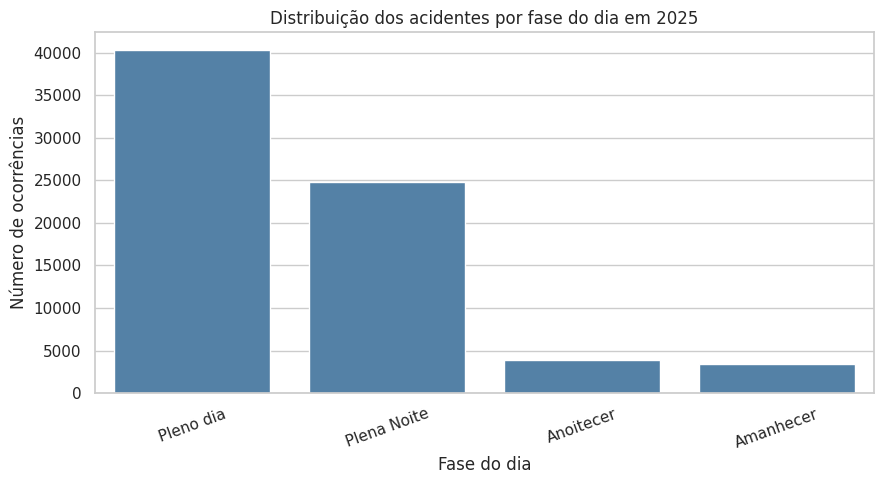

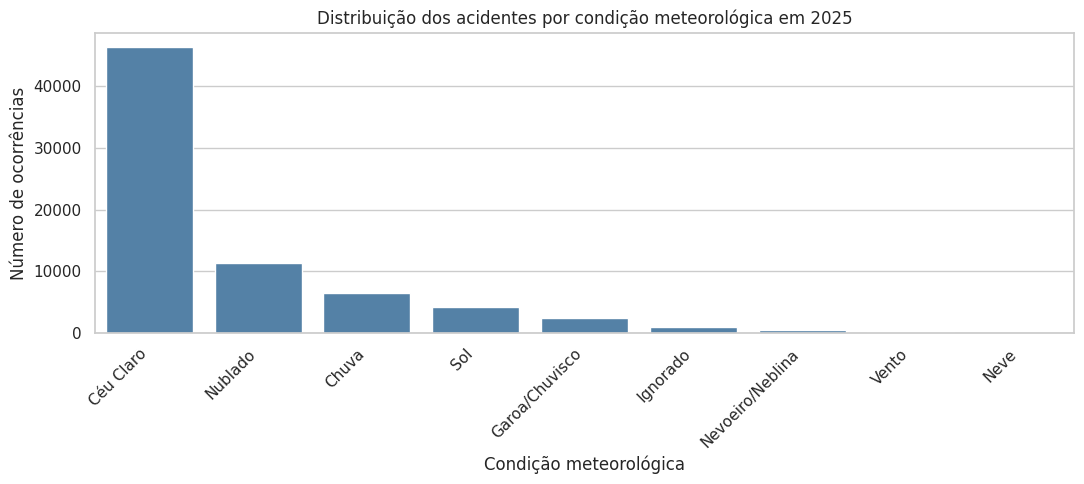

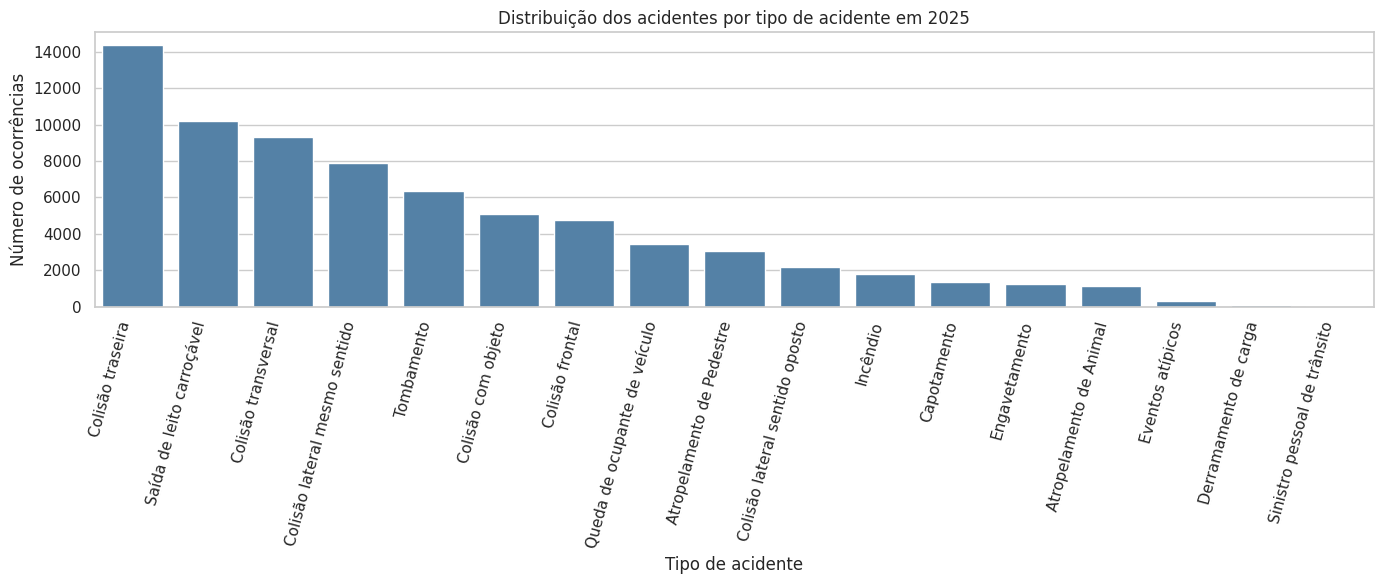

Valores ausentes por variável:
classificacao_acidente    1
tipo_pista                0
fase_dia                  0
condicao_metereologica    0
tipo_acidente             0
dtype: int64


In [5]:

#ANÁLISE UNIVARIADA

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Classificação dos acidentes

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    color="steelblue",
    x="classificacao_acidente",
    order=df["classificacao_acidente"].value_counts().index
)

plt.title("Classificação dos acidentes em 2025")
plt.xlabel("Classificação")
plt.ylabel("Número de ocorrências")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# 2. Distribuição por tipo de pista

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    color="steelblue",
    x="tipo_pista",
    order=df["tipo_pista"].value_counts().index
)

plt.title("Distribuição dos acidentes por tipo de pista em 2025")
plt.xlabel("Tipo de pista")
plt.ylabel("Número de ocorrências")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# 3. Distribuição por fase do dia

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    color="steelblue",
    x="fase_dia",
    order=df["fase_dia"].value_counts().index
)

plt.title("Distribuição dos acidentes por fase do dia em 2025")
plt.xlabel("Fase do dia")
plt.ylabel("Número de ocorrências")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# 4. Distribuição por condição meteorológica

plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    color="steelblue",
    x="condicao_metereologica",
    order=df["condicao_metereologica"].value_counts().index
)

plt.title("Distribuição dos acidentes por condição meteorológica em 2025")
plt.xlabel("Condição meteorológica")
plt.ylabel("Número de ocorrências")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# 5. Distribuição por tipo de acidente

plt.figure(figsize=(14, 6))

sns.countplot(
    data=df,
    color="steelblue",
    x="tipo_acidente",
    order=df["tipo_acidente"].value_counts().index
)

plt.title("Distribuição dos acidentes por tipo de acidente em 2025")
plt.xlabel("Tipo de acidente")
plt.ylabel("Número de ocorrências")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


# 6. Verificação dos valores ausentes

print("Valores ausentes por variável:")

print(
    df[[
        "classificacao_acidente",
        "tipo_pista",
        "fase_dia",
        "condicao_metereologica",
        "tipo_acidente"
    ]].isna().sum()
)


**1. Classificação dos acidentes**

A maior parte dos 72.529 acidentes registrados em 2025 foi classificada como ocorrência com vítimas feridas, totalizando 56.181 registros, aproximadamente 77,5% da base. Os acidentes sem vítimas aparecem em segundo lugar, enquanto os acidentes fatais representam a menor parcela. Essa distribuição mostra que a maioria das ocorrências registradas envolveu ferimentos, embora a frequência de cada classificação não permita avaliar individualmente o risco enfrentado pelos motoristas.

**2. Tipo de pista**

As pistas simples concentraram o maior número de acidentes, com 34.733 ocorrências, aproximadamente 47,9% do total. As pistas duplas apresentaram uma frequência próxima, enquanto as pistas múltiplas registraram uma quantidade consideravelmente menor. Entretanto, essa distribuição não significa necessariamente que pistas simples sejam mais perigosas, pois seria necessário considerar a extensão de cada tipo de rodovia e o volume de veículos que circulam nelas.

**3. Fase do dia**

Os acidentes ocorreram predominantemente durante o pleno dia, com 40.375 registros, correspondentes a aproximadamente 55,7% do total. O período de plena noite apresentou a segunda maior frequência, enquanto o anoitecer e o amanhecer tiveram quantidades menores. Essa distribuição pode estar relacionada às diferenças no fluxo de veículos ao longo do dia, embora os dados não permitam confirmar essa explicação isoladamente.

**4. Condição meteorológica**

A condição de céu claro apresentou a maior frequência, com 46.375 acidentes, aproximadamente 63,9% dos registros. Em seguida aparecem as condições de tempo nublado, com 11.435 ocorrências, e chuva, com 6.438. Entretanto, isso não significa que condições meteorológicas favoráveis aumentem o risco de acidentes, pois a distribuição também depende da frequência dessas condições e da exposição dos motoristas.

**5. Tipo de acidente**

A colisão traseira foi a modalidade mais frequente, com 14.360 registros, correspondentes a aproximadamente 19,8% dos acidentes. Em seguida aparecem as saídas de leito carroçável e as colisões transversais. Essa distribuição evidencia a predominância de determinadas modalidades de ocorrência, mas não permite identificar diretamente suas causas ou determinar quais apresentam maior gravidade.

**6. Análise dos valores ausentes**

A verificação dos valores nulos mostrou que as quatro variáveis analisadas, tipo de pista, fase do dia, condição meteorológica e tipo de acidente, não apresentam registros ausentes identificados pelo Pandas. Entretanto, a variável meteorológica contém 1.000 registros classificados como "Ignorado", o que corresponde a aproximadamente 1,4% da base. Embora esses valores não sejam reconhecidos como nulos, representam informações desconhecidas e precisam ser considerados na interpretação.

**Conclusão**

A análise univariada revelou uma predominância de acidentes com vítimas feridas, ocorridos em pistas simples, durante o pleno dia e sob condições de céu claro. As colisões traseiras também se destacaram como a modalidade mais frequente. Esses resultados permitem caracterizar os padrões gerais das ocorrências registradas pela PRF em 2025. Contudo, as frequências isoladas não demonstram relações causais nem permitem estimar o risco associado a cada condição, sendo necessárias análises adicionais que considerem outras variáveis e medidas de exposição.

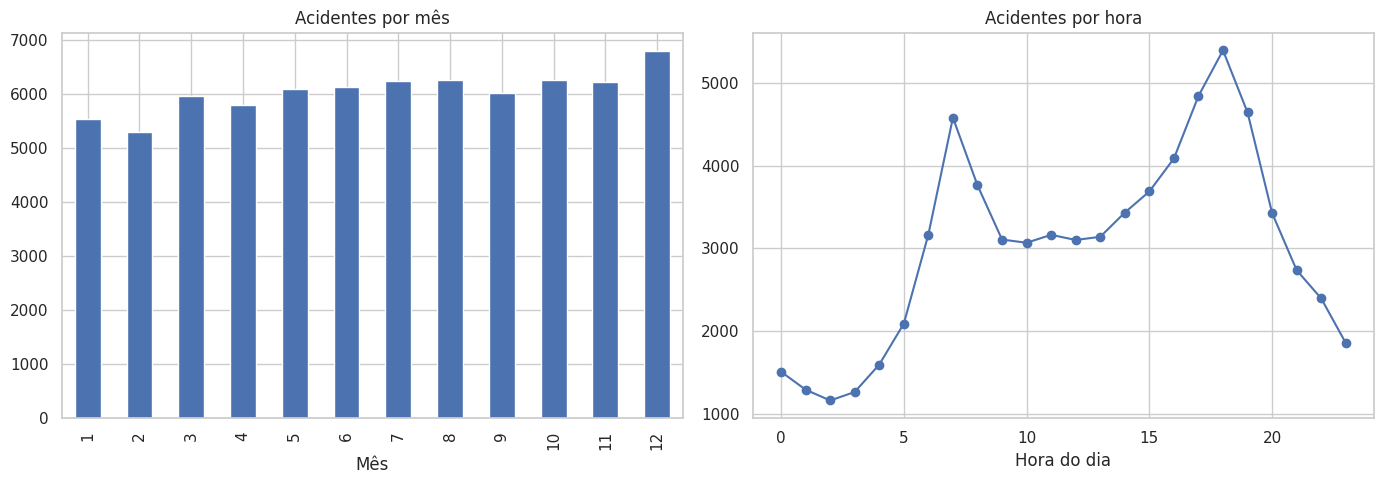

In [6]:
#Quais meses e horários ocorreram mais acidentes ?

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["mes"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0],
    title="Acidentes por mês"
)

df["hora"].value_counts().sort_index().plot(
    kind="line",
    marker="o",
    ax=axes[1],
    title="Acidentes por hora"
)

axes[0].set_xlabel("Mês")
axes[1].set_xlabel("Hora do dia")

plt.tight_layout()
plt.show()

Na base analisada, **dezembro** apresentou **6.788 ocorrências** e o horário das **18h** registrou **5.398 acidentes**.

A concentração de ocorrências em determinados meses e horários pode refletir mudanças no fluxo de veículos, na exposição ao trânsito e nas condições de circulação. Sem dados sobre o volume de tráfego, não podemos afirmar que esses horários são necessariamente os mais perigosos para motoristas.


ANÁLISE: TIPO DE PISTA


,total,fatais,percentual_fatal
tipo_pista,,,
Simples,34733,3424,9.86
Dupla,30782,1501,4.88
Múltipla,7014,285,4.06


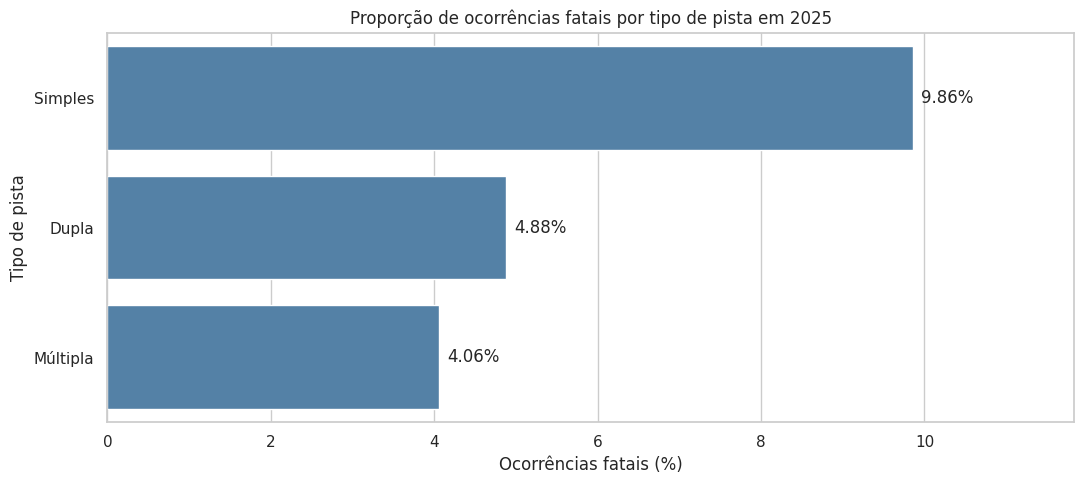


ANÁLISE: FASE DO DIA


,total,fatais,percentual_fatal
fase_dia,,,
Amanhecer,3447,386,11.20
Plena Noite,24781,2522,10.18
Anoitecer,3926,253,6.44
Pleno dia,40375,2049,5.07


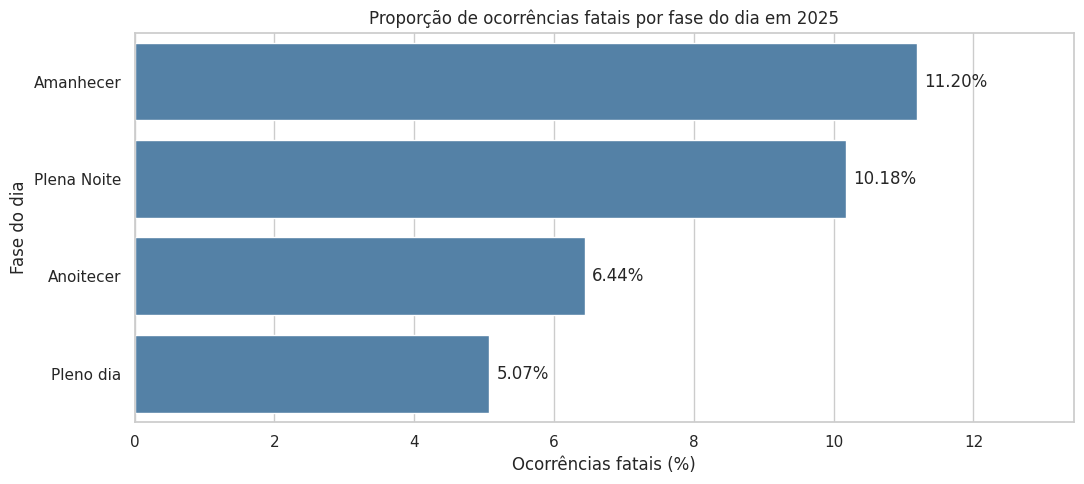


ANÁLISE: UNIDADE FEDERATIVA


,total,fatais,percentual_fatal
uf,,,
MA,1262,236,18.70
PA,1117,193,17.28
RR,142,23,16.20
AM,138,19,13.77
AL,629,86,13.67
TO,677,83,12.26
CE,1302,153,11.75
BA,4108,476,11.59
AC,280,29,10.36


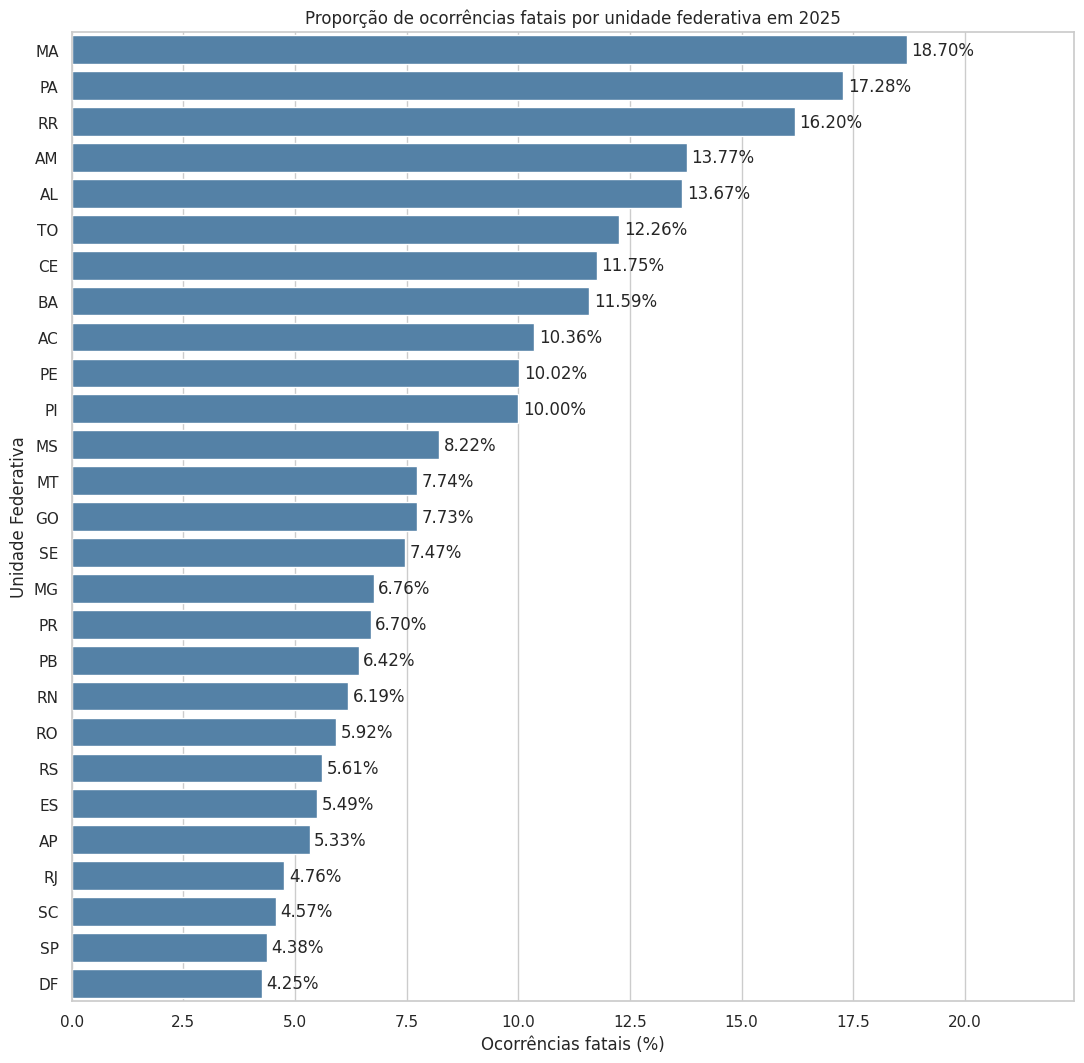


ANÁLISE: CAUSA DO ACIDENTE


,total,fatais,percentual_fatal
causa_acidente,,,
Suicídio (presumido),190,106,55.79
Pedestre andava na pista,606,250,41.25
Entrada inopinada do pedestre,667,203,30.43
Transitar na contramão,2475,736,29.74
Participar de racha,22,6,27.27
...,...,...,...
Declive acentuado,19,0,0.00
Redutor de velocidade em desacordo,8,0,0.00
Sinalização encoberta,2,0,0.00


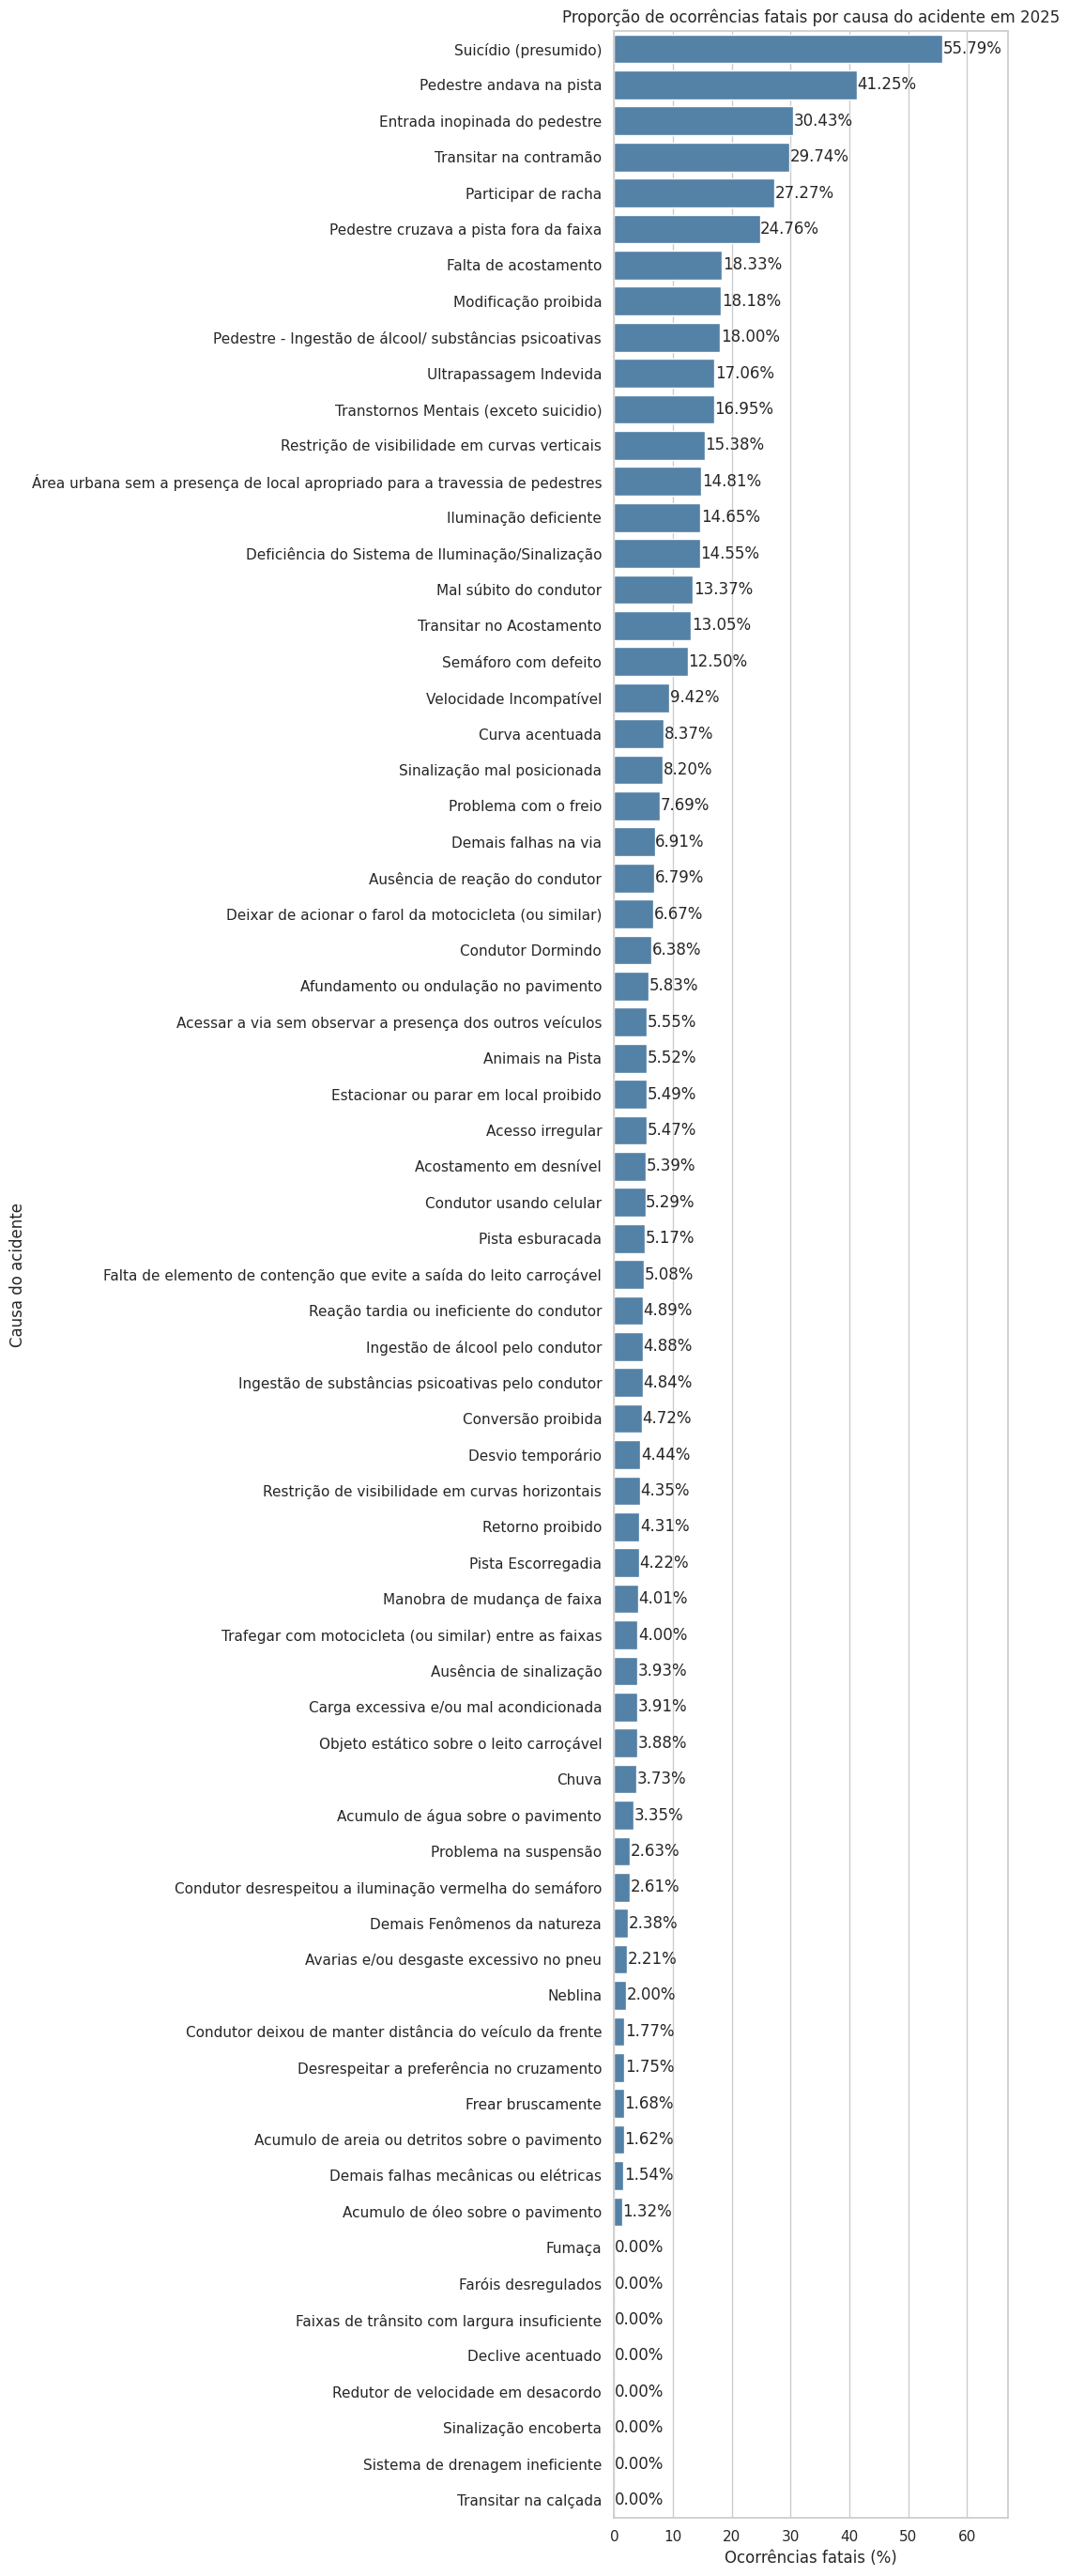

In [7]:
# ANÁLISE BIVARIADA

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Preparação dos dados

dados = df.copy()

dados["mortos_num"] = pd.to_numeric(
    dados["mortos"],
    errors="coerce"
)

# Remover registros sem informação válida sobre mortes
dados = dados.dropna(subset=["mortos_num"])

# Identificar acidentes com pelo menos uma morte
dados["ocorrencia_fatal"] = dados["mortos_num"] > 0


# Variáveis que serão analisadas

variaveis = {
    "tipo_pista": "Tipo de pista",
    "fase_dia": "Fase do dia",
    "uf": "Unidade Federativa",
    "causa_acidente": "Causa do acidente"
}


# Gerar tabelas e gráficos automaticamente

for coluna, nome in variaveis.items():

    print(f"\nANÁLISE: {nome.upper()}")

    # Agrupar os acidentes por categoria
    tabela = (
        dados.dropna(subset=[coluna])
        .groupby(coluna)
        .agg(
            total=("ocorrencia_fatal", "size"),
            fatais=("ocorrencia_fatal", "sum")
        )
    )

    # Calcular o percentual de acidentes fatais
    tabela["percentual_fatal"] = (
        tabela["fatais"] / tabela["total"] * 100
    )

    # Ordenar pelo percentual, do maior para o menor
    tabela = tabela.sort_values(
        "percentual_fatal",
        ascending=False
    )

    # Mostrar a tabela
    display(tabela.round(2))

    # Ajustar a altura conforme o número de categorias
    altura = max(5, len(tabela) * 0.4)

    plt.figure(figsize=(11, altura))

    # Gráfico de barras horizontais
    ax = sns.barplot(
        x=tabela["percentual_fatal"],
        y=tabela.index.astype(str),
        color="steelblue"
    )

    plt.title(
        f"Proporção de ocorrências fatais por {nome.lower()} em 2025"
    )

    plt.xlabel("Ocorrências fatais (%)")
    plt.ylabel(nome)

    # Mostrar os percentuais nas barras
    for i, valor in enumerate(tabela["percentual_fatal"]):
        ax.text(
            valor + 0.1,
            i,
            f"{valor:.2f}%",
            va="center"
        )

    plt.xlim(
        0,
        max(1, tabela["percentual_fatal"].max() * 1.2)
    )

    plt.tight_layout()
    plt.show()



A análise bivariada examinou a relação entre a ocorrência de acidentes fatais e quatro variáveis: tipo de pista, fase do dia, unidade federativa e causa do acidente. Os resultados foram calculados com base nos 72.529 registros da PRF de 2025.

**1. Tipo de pista**

As pistas simples apresentaram a maior proporção de acidentes fatais, com 9,86%, enquanto as pistas duplas registraram 4,88% e as múltiplas, 4,06%. Isso significa que, entre os acidentes registrados em pistas simples, a proporção de ocorrências fatais foi aproximadamente duas vezes maior que nas pistas duplas. Essa diferença pode estar associada a características como separação dos fluxos de veículos, velocidade e condições estruturais das rodovias. Entretanto, os resultados não permitem afirmar que o tipo de pista seja, isoladamente, responsável pela maior fatalidade.

**2. Fase do dia**

O amanhecer apresentou a maior proporção de acidentes fatais, com 11,20%, seguido pela plena noite, com 10,18%. Em comparação, os percentuais foram menores durante o anoitecer (6,44%) e o pleno dia (5,07%). Embora o período diurno concentre o maior número absoluto de acidentes, as ocorrências registradas no amanhecer e durante a noite apresentam maior proporção de fatalidade. Essa diferença pode estar relacionada à visibilidade, ao cansaço dos condutores e às características do tráfego, mas essas hipóteses exigem análises adicionais.

**3. Unidade Federativa**

A proporção de acidentes fatais apresentou diferenças consideráveis entre os estados brasileiros. O Maranhão registrou o maior percentual, com 18,70%, seguido pelo Pará (17,28%) e Roraima (16,20%). Pernambuco apresentou 10,02%, enquanto o Distrito Federal registrou uma das menores proporções, com 4,25%. Essas diferenças podem refletir características das rodovias, padrões de circulação e condições de segurança viária. Entretanto, a comparação precisa considerar a quantidade de ocorrências em cada estado, especialmente em locais com poucos registros, nos quais os percentuais podem apresentar maior instabilidade.

**4. Causa do acidente**

A análise das causas revelou diferenças expressivas na proporção de acidentes fatais. Entre as categorias com maior percentual aparecem suicídio presumido (55,79%), pedestre andando na pista (41,25%), entrada inesperada de pedestre (30,43%) e trânsito na contramão (29,74%). Entretanto, as causas mais frequentes não são necessariamente aquelas com maior proporção de fatalidade. A ausência de reação do condutor, por exemplo, apresentou 11.469 ocorrências, mas uma proporção fatal de 6,79%. Esses resultados sugerem que algumas circunstâncias estão associadas a maior gravidade, embora não seja possível estabelecer relações causais apenas com essa análise.

**Conclusão da análise bivariada**

Os resultados indicam que a proporção de acidentes fatais varia consideravelmente conforme as características das ocorrências. As maiores proporções foram observadas em pistas simples, durante o amanhecer e a plena noite, além de determinadas unidades federativas e causas específicas. A comparação também demonstrou que as categorias com maior número absoluto de acidentes nem sempre apresentam os maiores percentuais de fatalidade. Contudo, essas associações são descritivas e podem ser influenciadas por outras variáveis, como velocidade, fluxo de veículos e condições das rodovias. Portanto, análises estatísticas adicionais são necessárias para avaliar a significância das diferenças observadas.

**Observação metodológica:** o percentual de acidentes fatais representa a proporção de ocorrências com pelo menos uma morte em cada categoria. Ele não corresponde à probabilidade individual de morte de um motorista ou passageiro.

1. ANÁLISE UNIVARIADA: NÚMERO DE PESSOAS
Primeiro quartil: 2.00
Terceiro quartil: 3.00
Intervalo interquartil: 1.00
Limite superior: 4.50


,Classificação,Quantidade,Percentual (%)
0,Normal,66169,91.23
1,Outlier,6360,8.77


Registros com número atípico de pessoas:


,id,pessoas,veiculos,mortos,feridos_leves,feridos_graves
54082,716289,76,2,4,29,9
16694,734818,73,4,0,0,1
32614,673084,71,1,0,0,0
11155,711782,69,4,5,2,10
10867,710458,69,5,11,20,22
1633,659998,69,3,0,0,0
70684,740829,65,2,0,1,0
20464,654624,63,5,0,3,0
47483,706383,62,3,0,2,4
37734,691808,60,2,2,1,0


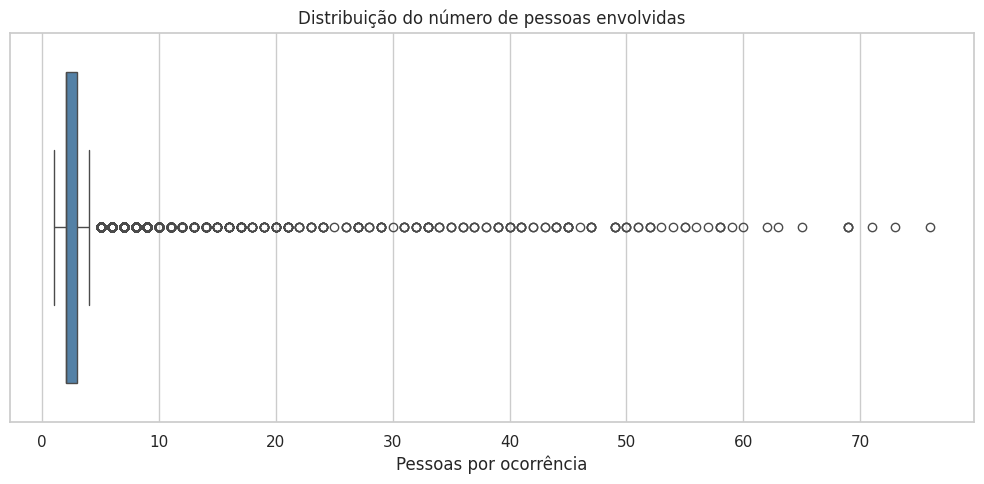


2. ANÁLISE MULTIVARIADA: ISOLATION FOREST
Registros analisados: 72529
Registros excluídos da análise: 0


,Classificação,Quantidade,Percentual (%)
0,Normal,71803,99.0
1,Outlier,726,1.0


Acidentes identificados como outliers multivariados:


,id,pessoas,veiculos,mortos,feridos_leves,feridos_graves
36,652842,7,4,1,0,3
43,652873,8,6,5,0,0
52,652931,17,8,0,1,0
80,653066,33,3,1,15,0
99,653188,7,3,2,1,2
319,654078,14,8,0,1,0
392,654400,7,4,0,3,2
396,654412,7,5,3,0,2
404,654449,17,6,0,3,2
420,654593,7,5,0,0,5


pessoas            veiculos            mortos             \
                 mean median max     mean median max   mean median max   
classificacao                                                            
Normal           2.51    2.0  73     1.98    2.0  82   0.07    0.0   5   
Outlier         11.64    8.0  76     4.16    3.0  31   1.20    1.0  16   

              feridos_leves            feridos_graves             
                       mean median max           mean median max  
classificacao                                                     
Normal                 0.85    1.0   9           0.26    0.0   7  
Outlier                3.53    2.0  41           2.18    2.0  22

In [8]:

# ETAPA 12. DETECÇÃO DE OUTLIERS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler

sns.set_theme(style="whitegrid")


# 1. OUTLIERS UNIVARIADOS: MÉTODO IQR

print("1. ANÁLISE UNIVARIADA: NÚMERO DE PESSOAS")

# Converter a variável para valores numéricos
pessoas = pd.to_numeric(df["pessoas"], errors="coerce")

# Considerar apenas valores válidos
pessoas_validas = pessoas.where(pessoas >= 0)

# Calcular os quartis
Q1 = pessoas_validas.quantile(0.25)
Q3 = pessoas_validas.quantile(0.75)

IQR = Q3 - Q1

# Calcular o limite superior
limite_superior = Q3 + 1.5 * IQR

# Identificar os outliers
df["outlier_pessoas"] = pd.Series(
    pd.NA,
    index=df.index,
    dtype="boolean"
)

validos_pessoas = pessoas_validas.notna()

df.loc[validos_pessoas, "outlier_pessoas"] = (
    pessoas_validas.loc[validos_pessoas] > limite_superior
)

# Mostrar os limites calculados
print(f"Primeiro quartil: {Q1:.2f}")
print(f"Terceiro quartil: {Q3:.2f}")
print(f"Intervalo interquartil: {IQR:.2f}")
print(f"Limite superior: {limite_superior:.2f}")

# Tabela 1. Resumo dos resultados

resumo_iqr = (
    df["outlier_pessoas"]
    .map({True: "Outlier", False: "Normal"})
    .fillna("Não analisado")
    .value_counts()
    .rename_axis("Classificação")
    .reset_index(name="Quantidade")
)

resumo_iqr["Percentual (%)"] = (
    resumo_iqr["Quantidade"] / len(df) * 100
).round(2)

display(resumo_iqr)

# Tabela 2. Acidentes identificados como outliers

colunas_exibir = [
    "id", "pessoas", "veiculos",
    "mortos", "feridos_leves", "feridos_graves"
]

outliers_iqr = df.loc[
    df["outlier_pessoas"].fillna(False),
    colunas_exibir
].copy()

outliers_iqr = outliers_iqr.sort_values(
    "pessoas", ascending=False
)

print("Registros com número atípico de pessoas:")
display(outliers_iqr.head(20))

# Gráfico: boxplot

plt.figure(figsize=(10, 5))

sns.boxplot(x=pessoas_validas.dropna(), color="steelblue")

plt.title("Distribuição do número de pessoas envolvidas")
plt.xlabel("Pessoas por ocorrência")
plt.tight_layout()
plt.show()


# 2. OUTLIERS MULTIVARIADOS: ISOLATION FOREST

print("\n2. ANÁLISE MULTIVARIADA: ISOLATION FOREST")

colunas = [
    "pessoas",
    "veiculos",
    "mortos",
    "feridos_leves",
    "feridos_graves"
]

# Converter as variáveis para valores numéricos
dados_numericos = df[colunas].apply(
    pd.to_numeric, errors="coerce"
)

# Tratar valores infinitos como ausentes
dados_numericos = dados_numericos.replace(
    [np.inf, -np.inf], np.nan
)

# Selecionar registros completos e não negativos
validos = (
    dados_numericos.notna().all(axis=1)
    & dados_numericos.ge(0).all(axis=1)
)

print("Registros analisados:", validos.sum())
print("Registros excluídos da análise:", (~validos).sum())

# Transformação logarítmica
X = np.log1p(dados_numericos.loc[validos])

# Escalonamento robusto
scaler = RobustScaler()
X = scaler.fit_transform(X)

# Modelo de detecção de anomalias
modelo = IsolationForest(
    contamination=0.01,
    random_state=42
)

previsoes = modelo.fit_predict(X)

# Criar coluna de classificação
df["outlier_multi"] = pd.Series(
    pd.NA,
    index=df.index,
    dtype="boolean"
)

df.loc[validos, "outlier_multi"] = previsoes == -1


# Tabela 3. Resumo dos resultados

resumo_multi = (
    df["outlier_multi"]
    .map({True: "Outlier", False: "Normal"})
    .fillna("Não analisado")
    .value_counts()
    .rename_axis("Classificação")
    .reset_index(name="Quantidade")
)

resumo_multi["Percentual (%)"] = (
    resumo_multi["Quantidade"] / len(df) * 100
).round(2)

display(resumo_multi)


# Tabela 4. Registros identificados como outliers

outliers_multi = df.loc[
    df["outlier_multi"].fillna(False),
    ["id"] + colunas
].copy()

print("Acidentes identificados como outliers multivariados:")
display(outliers_multi.head(20))


# Tabela 5. Comparação estatística

comparacao = (
    dados_numericos.loc[validos]
    .assign(
        classificacao=np.where(
            previsoes == -1,
            "Outlier",
            "Normal"
        )
    )
    .groupby("classificacao")[colunas]
    .agg(["mean", "median", "max"])
    .round(2)
)

display(comparacao)


**Análise univariada:** o método IQR identifica acidentes que apresentam um número de pessoas envolvidas superior ao limite estatístico calculado. O boxplot permite visualizar a distribuição e os valores extremos, enquanto as tabelas mostram quantos registros ultrapassaram esse limite.

**Análise multivariada:** o IsolationForest considera simultaneamente o número de pessoas, veículos, mortos e feridos. Dessa forma, consegue identificar combinações incomuns de características que não seriam necessariamente detectadas pela análise de uma única variável.

**Comparação estatística:** a última tabela permite verificar se os acidentes classificados como anômalos apresentam médias, medianas e valores máximos diferentes dos registros considerados normais.

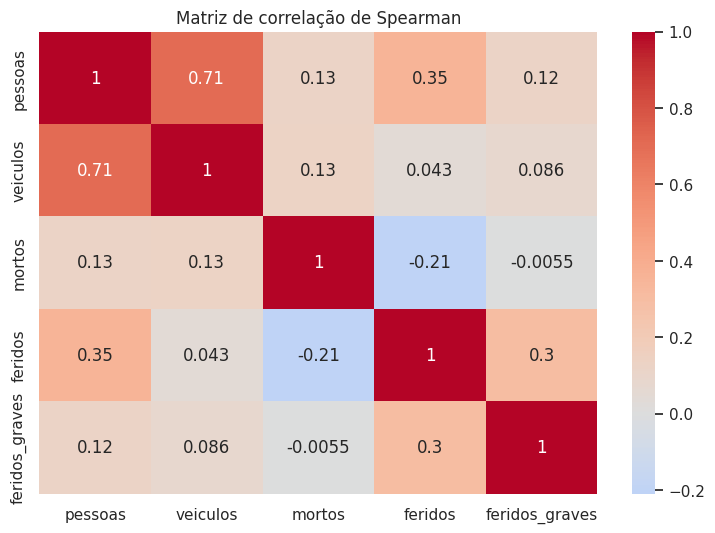

In [9]:
numericas = [
    "pessoas",
    "veiculos",
    "mortos",
    "feridos",
    "feridos_graves"
]

correlacao = df[numericas].corr(method="spearman")

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlação de Spearman")
plt.show()



**Correlação entre Variáveis Numéricas**

A correlação de Spearman foi utilizada para investigar as relações entre o número de pessoas envolvidas, veículos, mortos, feridos e feridos graves nos acidentes registrados pela PRF em 2025.

Os coeficientes variam entre **−1 e +1**. Valores positivos indicam associações crescentes, enquanto valores negativos representam associações decrescentes. Quanto mais próximo de zero, mais fraca tende a ser a associação monotônica entre as variáveis.

A matriz de correlação, representada por um mapa de calor, permite visualizar a direção e a intensidade dessas relações. Diferentemente da correlação de Pearson, o método de Spearman utiliza a classificação dos valores em postos, permitindo identificar associações monotônicas que não precisam ser lineares.

**Interpretação Estatística**

Algumas variáveis apresentam relações matemáticas entre si, especialmente o número total de feridos e o de feridos graves, já que os feridos graves fazem parte do total de feridos.

Assim, determinadas correlações podem refletir a própria estrutura dos registros, sem necessariamente indicar mecanismos independentes. Além disso, correlação não implica causalidade.

**Conclusão**

A análise de Spearman permite identificar padrões de associação entre as características numéricas dos acidentes. Entretanto, os coeficientes devem ser interpretados considerando a relação entre as variáveis e as limitações da base de dados. Como não foram calculados valores de significância estatística, a matriz permite avaliar a direção e a intensidade das associações observadas, mas não confirmar sua significância.




Tabela de contingência:


ocorrencia_fatal,Não fatal,Fatal
tipo_pista,,
Dupla,29281,1501
Múltipla,6729,285
Simples,31309,3424


Qui quadrado = 720.841
Graus de liberdade = 2
Valor p = 2.960e-157
Menor frequência esperada = 503.84
V de Cramér = 0.0997


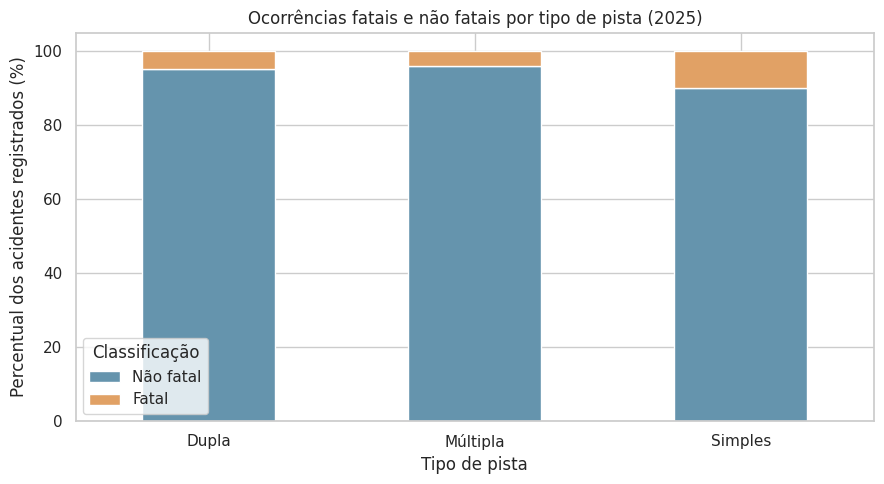

In [10]:
# 13. Teste qui quadrado e V de Cramér: tipo de pista e ocorrência fatal
from scipy.stats import chi2_contingency

tabela_pista = pd.crosstab(
    df["tipo_pista"],
    df["ocorrencia_fatal"],
    dropna=False
)

chi2, valor_p, graus_liberdade, frequencias_esperadas = chi2_contingency(
    tabela_pista
)

n = tabela_pista.to_numpy().sum()
min_dimensao = min(tabela_pista.shape) - 1
v_cramer = np.sqrt(chi2 / (n * min_dimensao))

print("Tabela de contingência:")
display(tabela_pista.rename(columns={False: "Não fatal", True: "Fatal"}))

print(f"Qui quadrado = {chi2:.3f}")
print(f"Graus de liberdade = {graus_liberdade}")
print(f"Valor p = {valor_p:.3e}")
print(f"Menor frequência esperada = {frequencias_esperadas.min():.2f}")
print(f"V de Cramér = {v_cramer:.4f}")

percentuais_pista = tabela_pista.div(tabela_pista.sum(axis=1), axis=0) * 100

ax = percentuais_pista.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#6594AD", "#E1A165"]
)
ax.set_title("Ocorrências fatais e não fatais por tipo de pista (2025)")
ax.set_xlabel("Tipo de pista")
ax.set_ylabel("Percentual dos acidentes registrados (%)")
ax.legend(["Não fatal", "Fatal"], title="Classificação")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Interpretação do teste de independência

A hipótese nula do teste qui quadrado considera que a ocorrência de pelo menos uma morte é independente do tipo de pista. Para a base analisada, a estatística foi **χ²(2) = 720,84**, com **p ≈ 2,96 × 10⁻¹⁵⁷**, oferecendo evidência estatística de associação entre essas variáveis. Todas as frequências esperadas superaram cinco, o que favorece a aplicação da aproximação do teste.

O **V de Cramér ≈ 0,100** mostra que a associação, embora estatisticamente detectável, é de pequena magnitude segundo referências usuais. A diferença entre 9,86% de ocorrências fatais em pistas simples e 4,88% em pistas duplas é descritivamente relevante, mas não pode ser atribuída apenas ao tipo de pista, já que características do tráfego e da infraestrutura podem atuar como variáveis de confusão.

A análise abrange somente acidentes registrados. Portanto, não fornece diretamente o risco de acidente por veículo ou quilômetro percorrido.

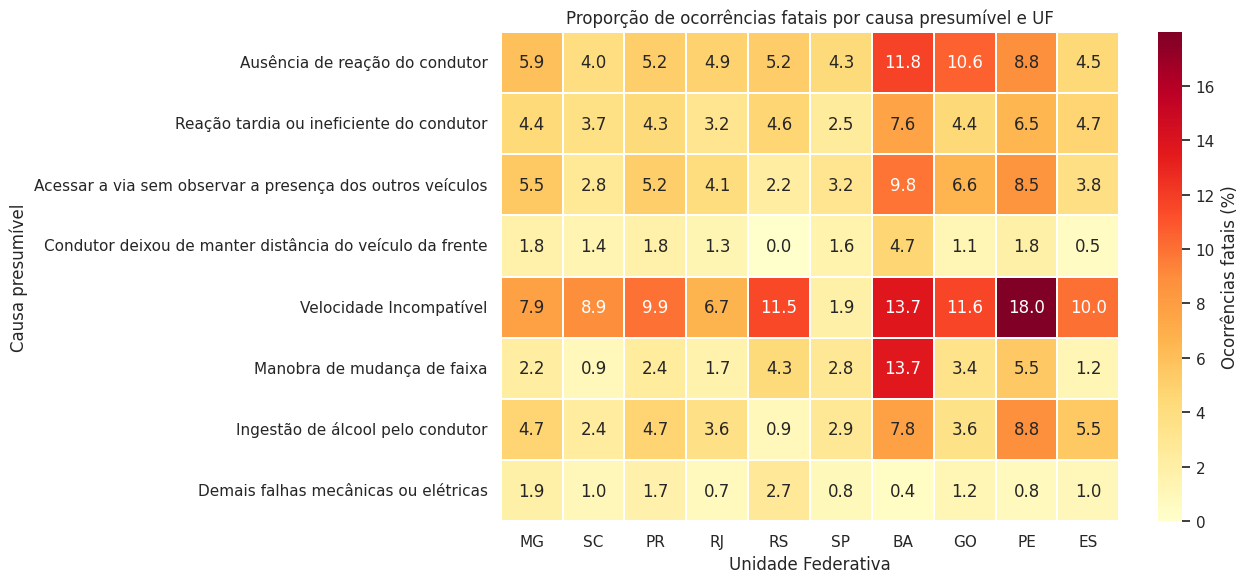

Número mínimo de ocorrências em cada célula exibida: 30
Células sem cor não atingiram o mínimo definido.


ocorrencias  fatais  \
causa_acidente                                     uf                        
Ausência de reação do condutor                     MG         1692     100   
Reação tardia ou ineficiente do condutor           PR         1329      57   
                                                   SC         1328      49   
Ausência de reação do condutor                     PR         1176      61   
Reação tardia ou ineficiente do condutor           MG         1164      51   
Velocidade Incompatível                            MG         1132      89   
Ausência de reação do condutor                     RJ         1112      54   
                                                   SC         1100      44   
Reação tardia ou ineficiente do condutor           RJ         1069      34   
                                                   SP         1054      26   
Ausência de reação do condutor                     SP          920      40   
Acessar a via sem observar a presença dos outro... SC          908      25   
Ausência de reação do condutor                     RS          768      40   
Acessar a via sem observar a presença dos outro... PR          695      36   
                                                   MG          690      38   

                                                       taxa_fatal_pct  
causa_acidente                                     uf                  
Ausência de reação do condutor                     MG            5.91  
Reação tardia ou ineficiente do condutor           PR            4.29  
                                                   SC            3.69  
Ausência de reação do condutor                     PR            5.19  
Reação tardia ou ineficiente do condutor           MG            4.38  
Velocidade Incompatível                            MG            7.86  
Ausência de reação do condutor                     RJ            4.86  
                                                   SC            4.00  
Reação tardia ou ineficiente do condutor           RJ            3.18  
                                                   SP            2.47  
Ausência de reação do condutor                     SP            4.35  
Acessar a via sem observar a presença dos outro... SC            2.75  
Ausência de reação do condutor                     RS            5.21  
Acessar a via sem observar a presença dos outro... PR            5.18  
                                                   MG            5.51

In [11]:
# 14. Cruzamento multivariado: causa presumível, fatalidade e UF
# Selecionar as oito causas mais frequentes e as dez UFs com mais ocorrências.
top_causas = df["causa_acidente"].value_counts().head(8).index
top_ufs = df["uf"].value_counts().head(10).index

recorte = df.loc[
    df["causa_acidente"].isin(top_causas) & df["uf"].isin(top_ufs),
    ["uf", "causa_acidente", "ocorrencia_fatal"]
].copy()

cruzamento = recorte.groupby(["causa_acidente", "uf"]).agg(
    ocorrencias=("ocorrencia_fatal", "size"),
    fatais=("ocorrencia_fatal", "sum")
)

cruzamento["taxa_fatal_pct"] = (
    100 * cruzamento["fatais"] / cruzamento["ocorrencias"]
)

# Evitar comparar percentuais instáveis de grupos muito pequenos.
minimo_grupo = 30
taxas = cruzamento["taxa_fatal_pct"].unstack("uf").reindex(
    index=top_causas, columns=top_ufs
)
contagens = cruzamento["ocorrencias"].unstack("uf").reindex(
    index=top_causas, columns=top_ufs
).fillna(0)

taxas_filtradas = taxas.where(contagens >= minimo_grupo)

plt.figure(figsize=(13, 6))
sns.heatmap(
    taxas_filtradas,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    cbar_kws={"label": "Ocorrências fatais (%)"},
    linewidths=0.3
)
plt.title("Proporção de ocorrências fatais por causa presumível e UF")
plt.xlabel("Unidade Federativa")
plt.ylabel("Causa presumível")
plt.tight_layout()
plt.show()

print("Número mínimo de ocorrências em cada célula exibida:", minimo_grupo)
print("Células sem cor não atingiram o mínimo definido.")
display(cruzamento.sort_values("ocorrencias", ascending=False).head(15).round(2))


**Interpretação do cruzamento multivariado**

O mapa de calor examina simultaneamente a causa presumível do acidente, a unidade federativa e a presença de mortes, permitindo observar diferenças que seriam ocultadas por análises separadas. O recorte inclui as oito causas mais frequentes e os dez estados com maior número de ocorrências.

A visualização apresenta apenas combinações com **pelo menos 30 acidentes registrados**, a fim de reduzir interpretações de percentuais baseados em amostras muito pequenas. Os grupos omitidos não foram apagados da base original. As causas registradas pela PRF também são classificações presumíveis e não devem ser interpretadas como demonstrações experimentais de causalidade.


In [12]:
# 15. Diagnóstico consolidado de qualidade dos dados
colunas_numericas = [
    "pessoas", "mortos", "feridos", "feridos_leves",
    "feridos_graves", "ilesos", "ignorados", "veiculos"
]

auditoria = {
    "Total de registros": len(df),
    "Colunas originais": 30,
    "IDs repetidos": int(df["id"].duplicated().sum()),
    "Datas inválidas": int(df["data"].isna().sum()),
    "Horas inválidas": int(df["hora"].isna().sum()),
    "Classificação de acidente ausente": int(
        df["classificacao_acidente"].isna().sum()
    ),
    'Meteorologia "Ignorado"': int(
        df["condicao_metereologica"].eq("Ignorado").sum()
    ),
    'Meteorologia "Neve"': int(
        df["condicao_metereologica"].eq("Neve").sum()
    ),
    "Divergência na soma de pessoas": int(
        df["pessoas"].ne(df["soma_pessoas"]).sum()
    ),
    "Divergência no total de feridos": int(
        df["feridos"].ne(df["feridos_leves"] + df["feridos_graves"]).sum()
    ),
    "Valores negativos nas contagens": int(
        df[colunas_numericas].lt(0).any(axis=1).sum()
    ),
    "Indicador fatal diferente de classificação": int(
        (
            df["classificacao_acidente"].notna()
            & df["ocorrencia_fatal"].ne(
                df["classificacao_acidente"].eq("Com Vítimas Fatais")
            )
        ).sum()
    )
}

tabela_auditoria = pd.Series(auditoria, name="Quantidade").to_frame()
display(tabela_auditoria)

# A quantidade de mortos soma pessoas, enquanto ocorrência fatal conta acidentes.
print("Número de acidentes com ao menos uma morte:",
      int(df["ocorrencia_fatal"].sum()))
print("Total de pessoas mortas registradas:", int(df["mortos"].sum()))

# Casos marcados para auditoria sem exclusão automática.
df["marcador_inconsistencia_pessoas"] = (
    df["pessoas"] != df["soma_pessoas"]
)
df["marcador_meteo_desconhecida"] = (
    df["condicao_metereologica"].eq("Ignorado")
)


,Quantidade
Total de registros,72529
Colunas originais,30
IDs repetidos,0
Datas inválidas,0
Horas inválidas,0
Classificação de acidente ausente,1
"Meteorologia ""Ignorado""",1000
"Meteorologia ""Neve""",1
Divergência na soma de pessoas,3823
Divergência no total de feridos,0


Número de acidentes com ao menos uma morte: 5210
Total de pessoas mortas registradas: 6043


**Diagnóstico e decisões de tratamento**

A auditoria encontrou **3.823 registros** em que a variável `pessoas` diverge da soma das categorias de envolvidos. Isso corresponde a aproximadamente **5,27%** da base. O fato de `feridos` coincidir com a soma de `feridos_leves` e `feridos_graves` indica consistência específica nesse campo, mas não resolve a divergência observada em `pessoas`.

Também foram identificados **1.000 registros** com condição meteorológica declarada como “Ignorado” e um registro com “Neve”. O segundo é atípico no contexto brasileiro, mas necessita verificação antes de ser considerado um erro. Há ainda uma classificação de acidente ausente, embora o registro apresente morte. Dessa forma, convém distinguir **5.210 ocorrências com ao menos uma morte**, obtidas a partir da coluna `mortos`, das **5.209 classificações preenchidas** como “Com Vítimas Fatais”.

| Problema observado | Proposta para análise e modelagem |
| :--- | :--- |
| Datas e horários originalmente textuais | Converter para tipos temporais e criar hora e mês |
| Valores nulos administrativos | Manter como desconhecidos ou imputar conforme a finalidade |
| Valor textual “Ignorado” | Preservar como categoria explícita de ausência informacional |
| Divergências entre contagens de pessoas | Criar marcador, verificar a origem e não corrigir por suposição |
| Observações estatisticamente extremas | Auditar e preservar eventos reais |
| Categorias nominais | Utilizar codificação indicadora com tratamento para novas categorias |
| Contagens numéricas assimétricas | Considerar transformação logarítmica e escalonamento robusto |
| Dados sobre o desfecho | Impedir vazamento de informação na escolha das variáveis preditoras |

Nenhum registro foi excluído ou alterado automaticamente em razão desses diagnósticos. As novas colunas constituem apenas variáveis derivadas e marcadores de controle.

In [13]:
# 16. Exemplo de preparação para uma modelagem futura
# Objetivo ilustrativo: classificar a fatalidade de um acidente já ocorrido
# com variáveis selecionadas que não contabilizam diretamente as vítimas.

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

categoricas = [
    "uf", "tipo_pista", "fase_dia",
    "condicao_metereologica", "uso_solo", "dia_semana"
]
numericas_modelo = ["hora", "mes"]

X_modelo = df[categoricas + numericas_modelo].copy()
y_modelo = df["ocorrencia_fatal"].astype(int)

# Separação temporal para reduzir vazamento entre meses.
treino = df["mes"].between(1, 9)
teste = df["mes"].between(10, 12)

X_treino, X_teste = X_modelo.loc[treino], X_modelo.loc[teste]
y_treino, y_teste = y_modelo.loc[treino], y_modelo.loc[teste]

preprocessador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            Pipeline(steps=[
                ("imputacao", SimpleImputer(
                    strategy="constant", fill_value="Não informado"
                )),
                ("codificacao", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categoricas
        ),
        (
            "numericas",
            Pipeline(steps=[
                ("imputacao", SimpleImputer(strategy="median")),
                ("escala", RobustScaler())
            ]),
            numericas_modelo
        )
    ]
)

# Ajustar transformações SOMENTE no conjunto de treino.
X_treino_preparado = preprocessador.fit_transform(X_treino)
X_teste_preparado = preprocessador.transform(X_teste)

print("Treino: janeiro a setembro:", len(X_treino), "ocorrências")
print("Teste: outubro a dezembro:", len(X_teste), "ocorrências")
print("Variáveis preparadas:", X_treino_preparado.shape[1])
print("Proporção fatal no treino:", round(y_treino.mean() * 100, 2), "%")
print("Proporção fatal no teste:", round(y_teste.mean() * 100, 2), "%")
print("Resultado: pré-processamento concluído, sem treino de modelo.")

# Não incluir 'mortos', 'feridos', 'pessoas' ou 'classificacao_acidente'
# como preditores desse desfecho por risco de vazamento de informação.


Treino: janeiro a setembro: 53280 ocorrências
Teste: outubro a dezembro: 19249 ocorrências
Variáveis preparadas: 54
Proporção fatal no treino: 7.25 %
Proporção fatal no teste: 6.99 %
Resultado: pré-processamento concluído, sem treino de modelo.


In [14]:
# 17. Resumo e verificável dos resultados
resultado_final = pd.DataFrame({
    "Indicador": [
        "Ocorrências registradas",
        "Ocorrências fatais segundo a coluna mortos",
        "Total de mortes registradas",
        "Registros com divergência nas contagens",
        "Registros outliers univariados (IQR)",
        "Registros outliers multivariados (Isolation Forest)",
        "Associação tipo de pista e fatalidade (V de Cramér)"
    ],
    "Valor": [
        f"{len(df):,}".replace(",", "."),
        f"{int(df['ocorrencia_fatal'].sum()):,}".replace(",", "."),
        f"{int(df['mortos'].sum()):,}".replace(",", "."),
        f"{int(df['marcador_inconsistencia_pessoas'].sum()):,}".replace(",", "."),
        f"{int(df['outlier_pessoas'].fillna(False).sum()):,}".replace(",", "."),
        f"{int(df['outlier_multi'].fillna(False).sum()):,}".replace(",", "."),
        f"{v_cramer:.4f}"
    ]
})

display(resultado_final)


,Indicador,Valor
0,Ocorrências registradas,72.529
1,Ocorrências fatais segundo a coluna mortos,5.210
2,Total de mortes registradas,6.043
3,Registros com divergência nas contagens,3.823
4,Registros outliers univariados (IQR),6.360
5,Registros outliers multivariados (Isolation Fo...,726
6,Associação tipo de pista e fatalidade (V de Cr...,0.0997


**Conclusão da Análise Exploratória de Dados**

A investigação dos registros da PRF de 2025 identificou **72.529 ocorrências**, das quais **5.210** tiveram ao menos uma morte, totalizando **6.043 óbitos registrados**. Acidentes com vítimas feridas constituíram a maior parte da base. O estudo temporal mostrou maior frequência de ocorrências em dezembro e no horário das 18h, enquanto os cruzamentos por tipo de pista e fase do dia evidenciaram diferenças na proporção de ocorrências fatais. Por exemplo, a proporção foi de **9,86% em pistas simples** e **4,88% em pistas duplas**, embora isso não permita concluir que a estrutura da pista seja a causa isolada da diferença.

A qualidade geral da base é favorável à análise exploratória, pois existem poucos valores nulos literais e não foram encontrados IDs repetidos. Entretanto, a auditoria revelou **3.823 divergências entre contagens de envolvidos**, além de informações desconhecidas representadas por categorias textuais e registros meteorológicos que merecem confirmação. A aplicação do IQR e do Isolation Forest ajudou a identificar observações atípicas. Essas observações, sobretudo acidentes com muitos envolvidos ou múltiplas vítimas, não devem ser excluídas automaticamente, pois podem representar justamente os eventos de maior interesse para a segurança rodoviária.

O teste qui quadrado encontrou associação entre tipo de pista e presença de mortes, mas o V de Cramér demonstrou que sua intensidade global é pequena. Além disso, como os dados contêm apenas acidentes registrados, não se pode estimar o risco por veículo ou distância percorrida sem incorporar medidas de exposição ao tráfego. Antes de construir modelos, recomenda-se auditar inconsistências, tratar explicitamente as categorias desconhecidas, aplicar codificação às variáveis categóricas e separar os períodos de treinamento e avaliação. Uma investigação futura também poderá integrar volume de tráfego e características das rodovias, permitindo interpretações mais ajustadas das diferenças entre regiões, horários e tipos de pista.

**Fonte dos dados:** Polícia Rodoviária Federal. *Dados Abertos: Acidentes de Trânsito em 2025, agrupados por ocorrência*. Disponível no portal de dados abertos da PRF.


### **ATIVIDADE 2**

In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!


In [16]:
# Carregamento da base oficial PRF 2025, independente do nome salvo pelo Colab.
import pandas as pd
from pathlib import Path
from zipfile import ZipFile, is_zipfile

# Usa o ZIP já presente na sessão, evitando solicitar novo envio.
candidatos = [Path("datatran2025.zip"), Path("/content/datatran2025.zip"),
              Path("/mnt/data/datatran2025.zip")]
candidatos += sorted(Path(".").glob("datatran2025*.zip"),
                     key=lambda p: p.stat().st_mtime, reverse=True)
caminho_zip = next((p for p in candidatos if p.is_file() and is_zipfile(p)), None)

if caminho_zip is None:
    try:
        from google.colab import files
    except ImportError as erro:
        raise FileNotFoundError(
            "Baixe datatran2025.zip no portal de dados da PRF e coloque o ZIP na pasta atual."
        ) from erro
    print("Envie o arquivo ZIP dos acidentes de 2025, agrupados por ocorrência.")
    enviados = files.upload()
    caminho_zip = next((Path(nome) for nome in enviados
                        if nome.lower().endswith(".zip") and is_zipfile(nome)), None)
    if caminho_zip is None:
        raise FileNotFoundError("Nenhum arquivo ZIP válido foi enviado.")

with ZipFile(caminho_zip) as zip_file:
    arquivos = [nome for nome in zip_file.namelist()
                if nome.lower().endswith(".csv")]
    nome_csv = next((nome for nome in arquivos
                     if "datatran2025" in nome.lower()), None)
    if nome_csv is None:
        raise ValueError("ZIP sem o CSV esperado: datatran2025.csv")
    with zip_file.open(nome_csv) as arquivo:
        df = pd.read_csv(arquivo, sep=";", encoding="latin1",
                         decimal=",", low_memory=False)

colunas_obrigatorias = {"id", "mortos", "pessoas", "data_inversa", "horario",
                        "uf", "tipo_pista", "condicao_metereologica"}
if not colunas_obrigatorias.issubset(df.columns):
    raise ValueError("O arquivo carregado não corresponde à base PRF 2025 esperada.")
print("Base carregada:", caminho_zip.name)
print("Dimensões:", df.shape)
display(df.head())

Base carregada: datatran2025 (1) (1).zip
Dimensões: (72529, 30)


,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
0,652493,2025-01-01,quarta-feira,06:20:00,SP,116,225.0,GUARULHOS,Reação tardia ou ineficiente do condutor,Tombamento,...,0,0,1,1,2,-23.485868,-46.540753,SPRF-SP,DEL01-SP,UOP01-DEL01-SP
1,652519,2025-01-01,quarta-feira,07:50:00,CE,116,546.2,PENAFORTE,Pista esburacada,Colisão frontal,...,0,1,4,1,6,-7.812288,-39.083333,SPRF-CE,DEL05-CE,UOP03-DEL05-CE
2,652522,2025-01-01,quarta-feira,08:45:00,PR,369,88.2,CORNELIO PROCOPIO,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,2,0,3,2,-23.182565,-50.637228,SPRF-PR,DEL07-PR,UOP05-DEL07-PR
3,652544,2025-01-01,quarta-feira,11:00:00,PR,116,74.0,CAMPINA GRANDE DO SUL,Reação tardia ou ineficiente do condutor,Saída de leito carroçável,...,0,4,0,1,2,-25.365177,-49.042230,SPRF-PR,DEL01-PR,UOP02-DEL01-PR
4,652549,2025-01-01,quarta-feira,09:30:00,MG,251,471.0,FRANCISCO SA,Velocidade Incompatível,Colisão frontal,...,1,1,2,2,4,-16.468013,-43.431213,SPRF-MG,DEL12-MG,UOP01-DEL12-MG


**Leitura da fonte e reprodutibilidade.** Este notebook utiliza o CSV `datatran2025.csv` armazenado no ZIP de acidentes agrupados por ocorrência de 2025 da PRF. Fonte: [Portal de Dados Abertos da PRF](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf). Para executar em uma nova sessão do Colab, disponibilize o ZIP quando solicitado na primeira célula de importação da Atividade 02. As informações são registros administrativos, sujeitos às limitações e possíveis inconsistências identificadas na auditoria.

In [17]:

# Verificar a estrutura da base
print("Informações gerais da base:")
df.info()

# Criar uma tabela com os tipos e valores ausentes
tabela_tipos = pd.DataFrame({
    "Tipo de dado": df.dtypes,
    "Valores ausentes": df.isnull().sum(),
    "Percentual de nulos (%)": (
        df.isnull().mean() * 100
    ).round(2)
})

display(tabela_tipos)

# Verificar registros duplicados
print("Linhas duplicadas:", df.duplicated().sum())
print("IDs repetidos:", df["id"].duplicated().sum())


Informações gerais da base:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72529 entries, 0 to 72528
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      72529 non-null  int64  
 1   data_inversa            72529 non-null  object 
 2   dia_semana              72529 non-null  object 
 3   horario                 72529 non-null  object 
 4   uf                      72529 non-null  object 
 5   br                      72529 non-null  int64  
 6   km                      72529 non-null  float64
 7   municipio               72529 non-null  object 
 8   causa_acidente          72529 non-null  object 
 9   tipo_acidente           72529 non-null  object 
 10  classificacao_acidente  72528 non-null  object 
 11  fase_dia                72529 non-null  object 
 12  sentido_via             72529 non-null  object 
 13  condicao_metereologica  72529 non-null  object 
 14  tipo_pista

,Tipo de dado,Valores ausentes,Percentual de nulos (%)
id,int64,0,0.00
data_inversa,object,0,0.00
dia_semana,object,0,0.00
horario,object,0,0.00
uf,object,0,0.00
br,int64,0,0.00
km,float64,0,0.00
municipio,object,0,0.00
causa_acidente,object,0,0.00
tipo_acidente,object,0,0.00


Linhas duplicadas: 0
IDs repetidos: 0


**Inspeção inicial dos dados**

Foram analisados os tipos das variáveis e a presença de valores ausentes e duplicados na base da PRF 2025. Essa verificação permite identificar atributos que precisam de conversão ou tratamento antes da aplicação dos algoritmos de aprendizado de máquina.

In [18]:

# Converter a data do acidente
df["data"] = pd.to_datetime(
    df["data_inversa"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Extrair a hora do acidente
df["hora"] = (
    pd.to_timedelta(
        df["horario"],
        errors="coerce"
    ).dt.total_seconds() // 3600
)

# Verificar horários válidos
df["hora"] = df["hora"].where(
    df["hora"].between(0, 23)
).astype("Int64")

# Extrair o mês
df["mes"] = df["data"].dt.month.astype("Int64")

# Converter variáveis de contagem
colunas_inteiras = [
    "pessoas",
    "mortos",
    "feridos",
    "feridos_leves",
    "feridos_graves",
    "ilesos",
    "ignorados",
    "veiculos"
]

for coluna in colunas_inteiras:
    df[coluna] = pd.to_numeric(
        df[coluna],
        errors="coerce"
    ).astype("Int64")

# Converter variáveis decimais
colunas_decimais = [
    "km",
    "latitude",
    "longitude"
]

for coluna in colunas_decimais:
    df[coluna] = pd.to_numeric(
        df[coluna].astype("string").str.replace(
            ",", ".", regex=False
        ),
        errors="coerce"
    )

# Identificadores e rodovias como texto
df["id"] = df["id"].astype("string")
df["br"] = df["br"].astype("string")

# Conferir os resultados
display(df[
    ["data", "hora", "mes", "pessoas",
     "mortos", "km", "latitude", "longitude"]
].head())

print("Conversão concluída!")


,data,hora,mes,pessoas,mortos,km,latitude,longitude
0,2025-01-01,6,1,2,0,225.0,-23.485868,-46.540753
1,2025-01-01,7,1,6,1,546.2,-7.812288,-39.083333
2,2025-01-01,8,1,5,0,88.2,-23.182565,-50.637228
3,2025-01-01,11,1,5,0,74.0,-25.365177,-49.04223
4,2025-01-01,9,1,5,0,471.0,-16.468013,-43.431213


Conversão concluída!


**Correção dos tipos de dados**

As variáveis temporais foram convertidas para formatos apropriados, permitindo extrair o mês e a hora de cada ocorrência. As variáveis relacionadas às quantidades de vítimas e veículos foram convertidas para números inteiros, enquanto quilometragem e coordenadas geográficas foram tratadas como valores decimais. Os identificadores foram mantidos como texto, pois não representam grandezas numéricas. Valores inválidos nas conversões foram identificados como ausentes para posterior tratamento.

In [19]:

# 1. Padronizar variáveis categóricas

categoricas = [
    "uf",
    "tipo_pista",
    "fase_dia",
    "condicao_metereologica",
    "uso_solo",
    "sentido_via",
    "dia_semana"
]

for coluna in categoricas:
    df[coluna] = (
        df[coluna]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .replace("", pd.NA)
    )

# 2. Verificar inconsistências nas contagens de pessoas

colunas_pessoas = [
    "mortos",
    "feridos_leves",
    "feridos_graves",
    "ilesos",
    "ignorados"
]

df["soma_pessoas"] = df[colunas_pessoas].sum(
    axis=1,
    min_count=5
)

df["inconsistencia_pessoas"] = (
    df["pessoas"].notna()
    & df["soma_pessoas"].notna()
    & (df["pessoas"] != df["soma_pessoas"])
)

# 3. Identificar valores negativos

colunas_contagem = [
    "pessoas", "mortos", "feridos",
    "feridos_leves", "feridos_graves",
    "ilesos", "ignorados", "veiculos"
]

df["valores_negativos"] = (
    df[colunas_contagem].lt(0).any(axis=1)
)

# 4. Verificar categorias meteorológicas suspeitas

meteorologia = df[
    "condicao_metereologica"
].value_counts(dropna=False)

# 5. Exibir o diagnóstico

print("Registros com divergência nas contagens:")
print(df["inconsistencia_pessoas"].sum())

print("\nRegistros com contagens negativas:")
print(df["valores_negativos"].sum())

print("\nMeteorologia classificada como Ignorado:")
print(meteorologia.get("Ignorado", 0))

print("\nMeteorologia classificada como Neve:")
print(meteorologia.get("Neve", 0))

print("\nExemplos de registros inconsistentes:")

display(
    df.loc[
        df["inconsistencia_pessoas"],
        ["id", "pessoas", "soma_pessoas"]
    ].head()
)


# Marcar a categoria meteorológica atípica para auditoria, sem excluir ocorrências.
df["meteorologia_neve_revisar"] = (
    df["condicao_metereologica"].eq("Neve").fillna(False)
)
print("Registros sinalizados para revisão meteorológica:",
      int(df["meteorologia_neve_revisar"].sum()))


Registros com divergência nas contagens:
3823

Registros com contagens negativas:
0

Meteorologia classificada como Ignorado:
1000

Meteorologia classificada como Neve:
1

Exemplos de registros inconsistentes:


,id,pessoas,soma_pessoas
1,652519,6,7
5,652569,4,5
22,652760,5,6
30,652812,4,5
33,652829,2,3


Registros sinalizados para revisão meteorológica: 1


### Identificação e tratamento de inconsistências

A análise comparou o total de pessoas envolvidas à soma das categorias de mortos, feridos, ilesos e ignorados. Os registros divergentes foram sinalizados e preservados, uma vez que a discrepância, isoladamente, não comprova erro no registro da ocorrência. As variáveis categóricas selecionadas foram padronizadas para remover espaços excedentes e identificar campos vazios.

A categoria meteorológica **"Neve"**, encontrada em um registro, foi mantida e marcada para verificação posterior, já que sua ocorrência incomum não é suficiente para justificar a alteração do dado. Registros com **"Ignorado"** são convertidos em informação ausente no conjunto de atributos usado pelo modelo. Assim, o pipeline pode representá-los como **"Não informado"**, sem substituir a ausência pela condição climática mais comum.

Essas decisões evitam a exclusão indiscriminada de ocorrências, preservam a rastreabilidade e permitem auditar os dados antes de qualquer correção definitiva.

In [20]:

# Selecionar as variáveis numéricas
numericas = [
    "km",
    "latitude",
    "longitude",
    "hora",
    "mes"
]

# Selecionar as variáveis categóricas
categoricas = [
    "uf",
    "tipo_pista",
    "fase_dia",
    "condicao_metereologica",
    "uso_solo",
    "sentido_via",
    "dia_semana"
]

# Criar uma cópia para a modelagem
dados_modelo = df[numericas + categoricas].copy()

# Padronizar categorias desconhecidas
for coluna in categoricas:
    dados_modelo[coluna] = (
        dados_modelo[coluna]
        .astype("string")
        .str.strip()
        .replace({
            "Ignorado": pd.NA,
            "Não Informado": pd.NA,
            "": pd.NA
        })
    )

# Calcular valores ausentes
tabela_nulos = pd.DataFrame({
    "Valores ausentes": dados_modelo.isna().sum(),
    "Percentual (%)": (
        dados_modelo.isna().mean() * 100
    ).round(2)
})

# Definir o tratamento planejado
tabela_nulos["Tratamento"] = [
    "Mediana no treino" if coluna in numericas
    else "Categoria Não informado no treino"
    for coluna in tabela_nulos.index
]

display(tabela_nulos)

print(
    "Valores ausentes na coluna mortos:",
    df["mortos"].isna().sum()
)


,Valores ausentes,Percentual (%),Tratamento
km,0,0.00,Mediana no treino
latitude,0,0.00,Mediana no treino
longitude,0,0.00,Mediana no treino
hora,0,0.00,Mediana no treino
mes,0,0.00,Mediana no treino
uf,0,0.00,Categoria Não informado no treino
tipo_pista,0,0.00,Categoria Não informado no treino
fase_dia,0,0.00,Categoria Não informado no treino
condicao_metereologica,1000,1.38,Categoria Não informado no treino
uso_solo,0,0.00,Categoria Não informado no treino


Valores ausentes na coluna mortos: 0


### Tratamento dos valores ausentes

Para os atributos numéricos, adotou-se imputação pela mediana, pois ela reduz o impacto de observações extremas sobre o valor utilizado no preenchimento. Nas variáveis categóricas, optou-se por criar a categoria **"Não informado"**, preservando a ausência de informação sem supor que a categoria mais frequente seja a correta. Nenhum valor é imputado usando informação do conjunto de validação ou de teste, já que as transformações são ajustadas somente no treino.

| Atributo | Critério de tratamento | Motivo |
| :--- | :--- | :--- |
| `km` | Mediana do treino | Quilometragens podem apresentar distribuição assimétrica |
| `latitude` e `longitude` | Mediana do treino | Evita eliminar registros, embora gere coordenadas artificiais, que não devem ser interpretadas geograficamente |
| `hora` | Mediana do treino | Preserva observações com horários ausentes, como estratégia inicial |
| `mes` | Mediana do treino | Mantém observações mesmo quando a data não é convertível |
| `uf` | "Não informado" | Evita atribuir um estado sem evidência |
| `tipo_pista` | "Não informado" | Não pressupõe uma configuração de pista |
| `fase_dia` | "Não informado" | Preserva a ausência de classificação temporal |
| `condicao_metereologica` | "Não informado" | Trata "Ignorado" sem inferir o clima |
| `uso_solo` | "Não informado" | Mantém a ausência como categoria própria |
| `sentido_via` | "Não informado" | Evita assumir o sentido mais comum |
| `dia_semana` | "Não informado" | Evita inventar uma categoria temporal |

A imputação de coordenadas pela mediana é uma solução de referência para testar o KNN, não uma reconstrução confiável da localização. Em análises futuras, pode ser preferível usar indicadores de ausência ou técnicas espaciais apropriadas.

In [21]:

# Criar a variável alvo
df["ocorrencia_fatal"] = (
    df["mortos"] > 0
).astype("Int64")

# Excluir apenas registros sem informação do alvo
validos = df["ocorrencia_fatal"].notna()

X = dados_modelo.loc[validos].copy()

y = df.loc[
    validos, "ocorrencia_fatal"
].astype(int)

print("Distribuição das classes:")
print(y.value_counts())

print("\nPercentual de cada classe:")
print((y.value_counts(normalize=True) * 100).round(2))


Distribuição das classes:
ocorrencia_fatal
0    67319
1     5210
Name: count, dtype: int64

Percentual de cada classe:
ocorrencia_fatal
0    92.82
1     7.18
Name: proportion, dtype: float64


In [22]:

# Selecionar uma amostra estratificada
X_amostra, _, y_amostra, _ = train_test_split(
    X,
    y,
    train_size=15000,
    stratify=y,
    random_state=42
)

# Separar treino e conjunto restante
X_treino, X_restante, y_treino, y_restante = train_test_split(
    X_amostra,
    y_amostra,
    test_size=0.40,
    stratify=y_amostra,
    random_state=42
)

# Dividir o restante entre validação e teste
X_validacao, X_teste, y_validacao, y_teste = train_test_split(
    X_restante,
    y_restante,
    test_size=0.50,
    stratify=y_restante,
    random_state=42
)

print("Treino:", len(X_treino))
print("Validação:", len(X_validacao))
print("Teste:", len(X_teste))


Treino: 9000
Validação: 3000
Teste: 3000


**Definição da variável alvo e divisão dos dados**

A variável alvo foi definida a partir da quantidade de mortes registradas em cada acidente, distinguindo ocorrências fatais e não fatais. Para reduzir o custo computacional do KNN, foi selecionada uma amostra estratificada de 15.000 registros, preservando aproximadamente a distribuição original das classes.

Os dados foram divididos em 60% para treinamento, 20% para validação e 20% para teste. Essa separação permite ajustar o modelo e comparar suas configurações sem utilizar antecipadamente as informações reservadas para a avaliação final.

In [23]:

# Preparar os tipos para o scikit-learn
for conjunto in [X_treino, X_validacao, X_teste]:

    for coluna in numericas:
        conjunto[coluna] = pd.to_numeric(
            conjunto[coluna],
            errors="coerce"
        ).astype(float)

    for coluna in categoricas:
        conjunto[coluna] = (
            conjunto[coluna]
            .astype(object)
            .where(conjunto[coluna].notna(), np.nan)
        )

# Criar os pipelines de pré-processamento
def criar_preprocessamento(escala="standard"):

    etapas_numericas = [
        ("imputacao", SimpleImputer(strategy="median"))
    ]

    if escala == "standard":
        etapas_numericas.append(
            ("escalonamento", StandardScaler())
        )

    elif escala == "minmax":
        etapas_numericas.append(
            ("escalonamento", MinMaxScaler())
        )

    etapas_categoricas = [
        ("imputacao", SimpleImputer(
            strategy="constant",
            fill_value="Não informado"
        )),
        ("encoding", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]

    preprocessador = ColumnTransformer(
        transformers=[
            (
                "numericas",
                Pipeline(etapas_numericas),
                numericas
            ),
            (
                "categoricas",
                Pipeline(etapas_categoricas),
                categoricas
            )
        ]
    )

    return preprocessador

# Criar uma configuração com StandardScaler
preprocessador_standard = criar_preprocessamento("standard")

# Ajustar usando APENAS os dados de treinamento
X_treino_transformado = preprocessador_standard.fit_transform(
    X_treino
)

print("Pré-processamento concluído!")

print("Dimensões antes:", X_treino.shape)
print("Dimensões depois:", X_treino_transformado.shape)

print("Valores ausentes após tratamento:",
      np.isnan(X_treino_transformado).sum())


Pré-processamento concluído!
Dimensões antes: (9000, 12)
Dimensões depois: (9000, 59)
Valores ausentes após tratamento: 0


### Codificação e escalonamento dos atributos

O **One Hot Encoding** transforma as variáveis nominais em indicadores numéricos sem introduzir uma ordem artificial entre categorias, como estados ou tipos de pista. Foram preservadas todas as categorias indicadoras. A chamada **dummy variable trap**, associada à colinearidade perfeita em determinados modelos lineares, não impede o uso do KNN. O parâmetro `handle_unknown="ignore"` permite transformar categorias não observadas no treinamento sem provocar erro.

Os atributos numéricos recebem imputação pela mediana e são comparados em três cenários: **sem escalonamento**, **StandardScaler** e **MinMaxScaler**. O cenário sem escalonamento ainda utiliza imputação e One Hot Encoding, por isso não equivale aos dados brutos sem qualquer tratamento. Essa comparação isola o efeito da escala numérica sobre o KNN, um algoritmo sensível às distâncias calculadas entre registros.

Os imputadores, codificadores e escalonadores são ajustados apenas com o conjunto de treino dentro de cada `Pipeline`, evitando **vazamento de dados**. Não foram incluídas contagens de mortos, feridos, classificação do acidente ou outras variáveis diretamente relacionadas à definição do desfecho entre os preditores.

In [24]:

# Criar uma função para montar os modelos KNN

def criar_modelo_knn(escala):

    modelo = Pipeline([
        (
            "preprocessamento",
            criar_preprocessamento(escala)
        ),
        (
            "knn",
            KNeighborsClassifier(
                n_neighbors=15,
                metric="minkowski",
                p=2
            )
        )
    ])

    return modelo


# Criar os três modelos

modelos = {
    "Sem escalonamento": criar_modelo_knn("nenhuma"),
    "StandardScaler": criar_modelo_knn("standard"),
    "MinMaxScaler": criar_modelo_knn("minmax")
}


# Criar um modelo de referência (baseline)

baseline = DummyClassifier(
    strategy="most_frequent"
)


# Treinar a baseline

baseline.fit(X_treino, y_treino)

print("Baseline treinada!")


# Treinar os modelos KNN

for nome, modelo in modelos.items():

    modelo.fit(X_treino, y_treino)

    print(f"Modelo {nome} treinado com sucesso!")


print("\nTreinamento concluído!")


Baseline treinada!
Modelo Sem escalonamento treinado com sucesso!
Modelo StandardScaler treinado com sucesso!
Modelo MinMaxScaler treinado com sucesso!

Treinamento concluído!


**Treinamento dos modelos KNN**

Foram treinadas três configurações do algoritmo KNN utilizando 15 vizinhos e distância euclidiana. A primeira utiliza os atributos numéricos sem escalonamento, enquanto as outras aplicam StandardScaler e MinMaxScaler, respectivamente.

Também foi criado um classificador de referência, que prevê sempre a classe majoritária. Essa baseline permitirá verificar se o KNN apresenta desempenho superior a uma estratégia simples de classificação.

O treinamento foi realizado exclusivamente com os dados destinados a essa finalidade, preservando os conjuntos de validação e teste para as próximas etapas.

In [25]:

# Criar uma função para avaliar os modelos

def avaliar_modelo(modelo, X, y):

    # Realizar as previsões
    previsoes = modelo.predict(X)

    # Calcular as probabilidades estimadas
    probabilidades = modelo.predict_proba(X)[:, 1]

    # Calcular as métricas
    return {
        "Acurácia": accuracy_score(y, previsoes),
        "Precisão": precision_score(
            y, previsoes, zero_division=0
        ),
        "Recall": recall_score(
            y, previsoes, zero_division=0
        ),
        "F1": f1_score(
            y, previsoes, zero_division=0
        ),
        "ROC AUC": roc_auc_score(
            y, probabilidades
        )
    }


# Avaliar o modelo de referência
resultados = {
    "Baseline": avaliar_modelo(
        baseline, X_validacao, y_validacao
    )
}

# Avaliar os três modelos KNN
for nome, modelo in modelos.items():

    resultados[nome] = avaliar_modelo(
        modelo, X_validacao, y_validacao
    )

# Organizar os resultados em tabela
tabela_resultados = pd.DataFrame(resultados).T

display(tabela_resultados.round(4))


,Acurácia,Precisão,Recall,F1,ROC AUC
Baseline,0.928,0.0,0.0,0.0,0.5000
Sem escalonamento,0.928,0.0,0.0,0.0,0.5260
StandardScaler,0.928,0.0,0.0,0.0,0.6026
MinMaxScaler,0.928,0.0,0.0,0.0,0.5944


In [26]:

# Identificar a configuração com maior ROC AUC
resultado_knn = tabela_resultados.drop(
    index="Baseline"
)

melhor_modelo = resultado_knn["ROC AUC"].idxmax()

print("Melhor configuração:", melhor_modelo)

print(
    "ROC AUC:",
    round(
        resultado_knn.loc[
            melhor_modelo, "ROC AUC"
        ],
        4
    )
)


Melhor configuração: StandardScaler
ROC AUC: 0.6026


**Avaliação dos modelos KNN**

Os modelos foram avaliados utilizando o conjunto de validação, considerando acurácia, precisão, recall, F1 e ROC AUC. A comparação incluiu um classificador de referência e três configurações do KNN, permitindo investigar a influência do escalonamento sobre o desempenho preditivo.

Como os acidentes fatais representam uma parcela minoritária da base, a acurácia não foi considerada isoladamente. As métricas de precisão, recall e F1 foram utilizadas para examinar a identificação da classe fatal, enquanto o ROC AUC permitiu comparar a capacidade discriminativa dos modelos. A configuração com maior ROC AUC na validação foi selecionada para a avaliação final.

Resultados no conjunto de teste:


,Acurácia,Precisão,Recall,F1,ROC AUC
Baseline,0.9283,0.0,0.0,0.0,0.5000
StandardScaler,0.9283,0.0,0.0,0.0,0.6329


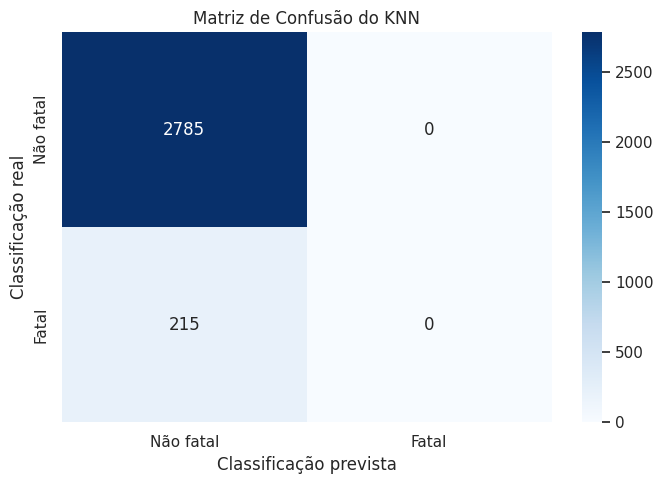

In [27]:

# Selecionar o melhor modelo da validação
modelo_final = modelos[melhor_modelo]

# Avaliar no conjunto de teste
resultados_teste = {
    "Baseline": avaliar_modelo(
        baseline, X_teste, y_teste
    ),
    melhor_modelo: avaliar_modelo(
        modelo_final, X_teste, y_teste
    )
}

# Criar tabela de resultados
tabela_teste = pd.DataFrame(resultados_teste).T

print("Resultados no conjunto de teste:")
display(tabela_teste.round(4))

# Fazer previsões
previsoes = modelo_final.predict(X_teste)

# Calcular matriz de confusão
matriz = confusion_matrix(
    y_teste,
    previsoes,
    labels=[0, 1]
)

# Gerar gráfico
plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Não fatal", "Fatal"],
    yticklabels=["Não fatal", "Fatal"]
)

plt.title("Matriz de Confusão do KNN")
plt.xlabel("Classificação prevista")
plt.ylabel("Classificação real")

plt.tight_layout()
plt.show()


## Conclusão da Atividade 02

A preparação da base da PRF 2025 incluiu conversão de tipos, auditoria de duplicatas e inconsistências, imputação de valores ausentes, One Hot Encoding e escalonamento dos atributos numéricos. Para verificar a influência da escala, foram treinadas três configurações do KNN, todas com 15 vizinhos e distância euclidiana, além de um classificador trivial que sempre prevê a classe majoritária. A análise utilizou uma amostra estratificada de 15.000 acidentes, separada em treino, validação e teste.

Na validação, a configuração com StandardScaler apresentou a maior ROC AUC (**0,6026**), superando o KNN sem escalonamento (**0,5260**), o MinMaxScaler (**0,5944**) e a baseline trivial (**0,5000**). Portanto, a padronização melhorou a capacidade discriminativa em relação à alternativa sem escalonamento. É importante observar que essa última alternativa ainda passou por imputação e codificação categórica.

No teste, o KNN com StandardScaler alcançou acurácia de **92,83%** e ROC AUC de **0,6329**. No limiar padrão de classificação, porém, previu todos os registros como não fatais e deixou de identificar as **215 ocorrências fatais**, resultando em recall e F1 iguais a zero para a classe positiva. A acurácia corresponde praticamente à do classificador trivial, o que evidencia a limitação dessa métrica em uma base desequilibrada.

Os resultados mostram uma melhora de discriminação com o escalonamento, mas **não demonstram capacidade satisfatória de identificar acidentes fatais no limiar adotado**. Em trabalhos futuros, podem ser examinados o ajuste do limiar usando exclusivamente a validação, estratégias para lidar com o desbalanceamento e métodos adicionais de classificação. Como a amostra foi extraída de acidentes já registrados, o modelo estima a fatalidade condicional ao acidente e não a probabilidade de um acidente ocorrer. A seleção por amostragem estratificada e a imputação de coordenadas também limitam a interpretação e a generalização dos resultados.